# Tiling: exploration and QC

This notebook checks the tiles written by `data_prep/tile.py` for the slides in subset B.
It only reads files; nothing here changes the data. Several cells call `tile.py`'s own functions
(mask, grid, slide opening), so they show exactly what the tiler does.

**How to use:** run the Setup and Settings cells first, then any section. Run it in the `gbm-mgmt`
conda environment. The cells read `patches/<version>/index_B.csv` and each slide's `.h5`,
`_patches.csv` and `_qc.png`, plus the QC decisions written by `data_prep/qc.py`.

Results from tiling-v2 to tiling-v6 are kept, with their outputs, in the History section at the end.


### Tiling config history

| Version | Grid and tile reads | Tissue mask |
|---|---|---|
| tiling-v1 | Custom grid in level-0 coordinates | TIAToolbox grayscale Otsu |
| tiling-v2 | TIAToolbox `SlidingWindowPatchExtractor` | TIAToolbox grayscale Otsu |
| tiling-v3 | TIAToolbox `SlidingWindowPatchExtractor` | Saturation channel, lower cut of a three-class Otsu |
| tiling-v4 | As v3, plus a quality filter that drops empty or featureless tiles | As v3 |
| tiling-v5 | Same tiles as v4. Adds per-tile glass and blur scores to each `.h5`, config validation, and rerun checks (code version, `.h5` size, QC image) | As v3 |
| tiling-v6 | As v5. A slide with no tiles is written with 0 tiles instead of failing | As v3, but the threshold is never below `mask_min_saturation` (8) |
| tiling-v7 (current) | 224 px tiles. Every tissue tile is scored and recorded; pixels are stored as lossless PNG with a pixel hash, for all tissue tiles or a seeded sample (`max_tiles_per_slide`). Tiles touching the mask are scored in `_patches.csv`. No quality filter in tiling: `qc.py` applies `configs/qc_policy.yaml`. Outputs in `patches/tiling-v7/` | As v6, plus a two-class option for comparison; each slide records whether the floor was applied |

## Setup

All imports for the notebook, including the pipeline modules from the repo's `data_prep/` folder (set by
`REPO`): `common.py` (config, paths), `slides.py` (mask, grid, scores), `qc.py`, `review.py` and `loader.py`.
Run this first. Importing TIAToolbox takes several seconds because it loads PyTorch.

In [3]:
import hashlib
import io
import json
import sys
from pathlib import Path
from tqdm.auto import tqdm
import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# The repo's data_prep/ scripts. Cells call the pipeline's own functions (mask, grid, slide opening), so what
# they show is what the tiler does.
REPO = Path("~/Bioinformatics/WSI/gbm-mgmt-wsi").expanduser()
sys.path.insert(0, str(REPO / "data_prep"))
import common                                  # noqa: E402
import loader                                  # noqa: E402
import qc                                      # noqa: E402
import review                                  # noqa: E402
import slides                                  # noqa: E402
import split                                   # noqa: E402
from download import DEFAULT_MANIFEST, load_manifest, paths_for  # noqa: E402

### Settings

Used by every section below.

- `ROOT`: the data folder that `download.py` and `tile.py` write to
- `SUBSET`: which `index_<SUBSET>.csv` to read
- `SEED`: picks the random slides and the random tiles; the same seed shows the same ones every run
- `SLIDES`: 10 random slides from `index_<SUBSET>.csv`, picked with `SEED`
- `GRID`: tiles per side of each tile grid (4 → 16 tiles)
- `SCALE_BAR_UM`: length of the scale bar drawn on each tile grid

The tiling config and QC policy are read from the repo's `configs/`, so the notebook reads the outputs of
the current config version (`patches/<version>/`). The helper functions below are shared by the sections.
Each section sets its own slide list at the top of its cell (`MASK_SLIDE`, `CHECK_SLIDES`, ...), so none of
them overwrites `SLIDES`.

In [4]:
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
SEED = 2026         # seed for reproducibility of slides and tiles
GRID = 4            # GRID x GRID tiles per slide
SCALE_BAR_UM = 20

CFG = common.load_tiling_config(REPO / "configs" / "tiling.yaml")[0]
POLICY = qc.load_policy(REPO / "configs" / "qc_policy.yaml")[0]
VERSION = CFG["version"]
TILED = ROOT / "patches" / CFG["version"]          # this config version's outputs
index = pd.read_csv(TILED / f"index_{SUBSET}.csv")
# get 10 random slides from the index for visualization
SLIDES = index.sample(n=min(10, len(index)), random_state=SEED).slide_id.tolist()
print(f"{CFG['version']}: {len(index)} tiled slides in index_{SUBSET}.csv | QC policy {POLICY['version']}")


def find_slide(key):
    # The index row for a slide ID or file-name prefix; exactly one slide must match.
    match = index[(index.slide_id == key) | index.file_name.str.startswith(key)]
    if len(match) != 1:
        raise ValueError(f"{key}: {len(match)} matching slides in index_{SUBSET}.csv")
    return match.iloc[0]


def slide_file(row):
    # The slide's .svs under ROOT/raw/.
    return paths_for(ROOT, {k: getattr(row, k) for k in ("source", "patient_id", "slide_id", "file_name")})[0]


def patches_table(row):
    # The slide's _patches.csv: one row per tissue or edge tile, with its scores and pixel hash.
    return pd.read_csv(ROOT / row.csv)


def read_stored(row, h5_indices):
    # Decode stored tiles (lossless PNG) by their row in the slide's .h5.
    with h5py.File(ROOT / row.h5) as h5:
        return [np.asarray(Image.open(io.BytesIO(h5["tiles"][int(i)].tobytes()))) for i in h5_indices]

tiling-v7: 6 tiled slides in index_B.csv | QC policy qc-v1


## Slides at a glance

One row per tiled slide, from the receipts in the index (no images are read): native resolution and the
upsampling applied, the Otsu cut and the threshold actually used, whether the floor was applied, tile
counts, `.h5` size and time. Slides where the floor was applied are listed first. Then the cost so far and a
rough projection to the whole subset, which matters now that there is no 2,000-tile cap.

- `n_grid`: complete 224 px grid positions on the slide
- `n_tissue_tiles`: tissue tiles (more than half tissue); all are scored and recorded
- `n_stored_tiles`: tissue tiles whose pixels are stored (all of them, or `max_tiles_per_slide`)
- `n_edge_tiles`: tiles touching the mask but not more than half tissue (scored, not stored)
- `seconds`: time one worker spent on the slide; total wall time is about the sum divided by `--workers`

**Results (tiling-v7):** to fill in after the run.

In [5]:
# One row per tiled slide: resolution, mask, tile counts, storage and time (from the receipts; no images).
glance = index.assign(file=index.file_name.str[:23], h5_MB=(index.h5_bytes / 1e6).round(1),
                      upsample_pct=index.upsample_pct.round(2), mask_fraction=index.mask_fraction.round(3))[
    ["source", "patient_id", "file", "source_mpp", "upsample_pct", "mask_otsu_threshold", "mask_threshold",
     "mask_floor_applied", "mask_fraction", "n_grid", "n_tissue_tiles", "n_stored_tiles", "n_edge_tiles",
     "h5_MB", "seconds"]]
display(glance.sort_values(["mask_floor_applied", "n_tissue_tiles"], ascending=[False, True]))

floor = glance[glance.mask_floor_applied]
print(f"Floor applied on {len(floor)} slides" + (": " + ", ".join(floor.file) if len(floor) else ""))
empty = glance[glance.n_tissue_tiles == 0]
print(f"No tissue tiles on {len(empty)} slides" + (": " + ", ".join(empty.file) if len(empty) else ""))

# Cost so far, and a rough projection to the whole subset (assumes the same mix of slides).
_, manifest = load_manifest(DEFAULT_MANIFEST)
all_files = manifest["files"]
subset_n = len(split.select_files(all_files, SUBSET, split.build_patient_split(all_files)))
cap = CFG["max_tiles_per_slide"]
print(f"Tiling cap: {cap} stored tiles per slide" if cap else "Tiling cap: none (every tissue tile stored)")
print(f"Tiled {len(index)} of {subset_n} slides: {index.n_tissue_tiles.sum():,} tissue tiles, "
      f"{index.n_stored_tiles.sum():,} stored, "
      f"{index.h5_bytes.sum() / 1e9:.2f} GB, {index.seconds.sum() / 3600:.2f} worker-hours")
print(f"Projected for all {subset_n} slides: about {index.h5_bytes.mean() / 1e9 * subset_n:.1f} GB and "
      f"{index.seconds.mean() * subset_n / 3600:.1f} worker-hours")

,source,patient_id,file,source_mpp,upsample_pct,mask_otsu_threshold,mask_threshold,mask_floor_applied,mask_fraction,n_grid,n_tissue_tiles,n_stored_tiles,n_edge_tiles,h5_MB,seconds
2,CPTAC,C3N-02786,C3N-02786-23.svs,0.4942,0.0,26.0,26.0,False,0.108,10656,1182,1182,379,115.8,8.7
1,CPTAC,C3N-02786,C3N-02786-22.svs,0.4942,0.0,31.0,31.0,False,0.133,13653,1841,1841,492,190.1,12.8
0,CPTAC,C3N-02786,C3N-02786-21.svs,0.4942,0.0,31.0,31.0,False,0.161,12198,1996,1996,308,209.0,13.0
5,TCGA,TCGA-12-0819,TCGA-12-0819-01Z-00-DX1,0.4993,0.0,41.0,41.0,False,0.368,10720,4037,4037,1052,393.5,28.3
4,TCGA,TCGA-12-0819,TCGA-12-0819-01Z-00-DX3,0.4993,0.0,46.0,46.0,False,0.122,57408,7114,5508,1248,570.1,45.6
3,TCGA,TCGA-12-0819,TCGA-12-0819-01Z-00-DX2,0.4993,0.0,46.0,46.0,False,0.193,57408,11167,5508,1823,576.5,66.4


Floor applied on 0 slides
No tissue tiles on 0 slides
Tiling cap: 5508 stored tiles per slide
Tiled 6 of 259 slides: 27,337 tissue tiles, 20,072 stored, 2.06 GB, 0.05 worker-hours
Projected for all 259 slides: about 88.7 GB and 2.1 worker-hours


## Tissue mask, step by step

For one slide (`MASK_SLIDE`), the mask calculation one step at a time, using `tile.py`'s own functions:

- **Top row:** the RGB thumbnail at `mask_mpp`, its HSV saturation, its brightness, and the median-blurred
  saturation that Otsu actually sees. Brightness is shown because the mask uses saturation only: dark but
  colored areas (folds, ink) pass it, and the darkness checks catch them later.
- **Bottom row:** the histogram of the blurred saturation (log scale) with each variant's threshold, then the
  mask (green) from a two-class Otsu, a three-class Otsu without the floor, and a three-class Otsu with the
  config's floor. All three share the thumbnail, blur and closing, so they differ only in the number of Otsu
  classes and the floor.

The table below the figure gives each variant's cut, masked share and number of tissue tiles.
`tile.py --masks-only` saves the same three-way comparison as an image for many slides at once.

**What to check (with Couger):** pale regions, tissue edges, small islands, and background. The goal is to
keep readable tissue without pulling in glass, dust or shading; a larger mask is not better by itself. Good
slides to try: those with `mask_floor_applied` in the table above, and strongly stained slides with pale areas.

**Results (tiling-v7):** to fill in after the review.

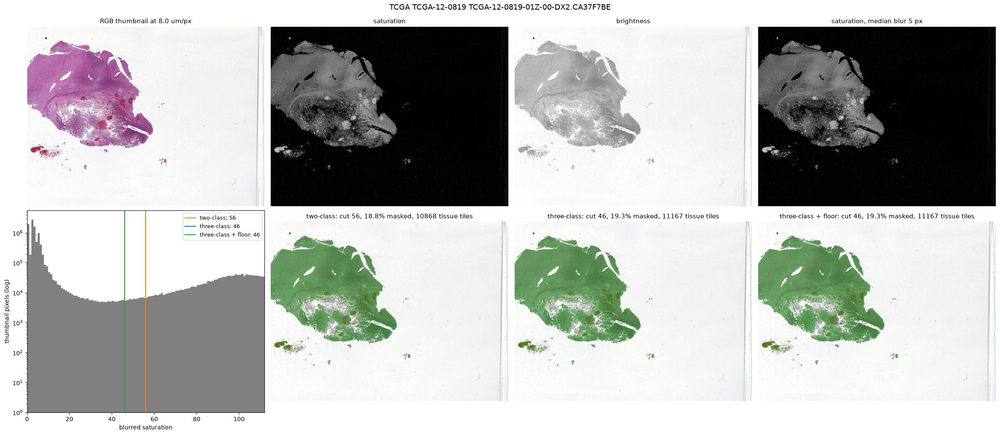

,variant,otsu_cut,threshold_used,masked_pct,tissue_tiles
0,two-class,56.0,56.0,18.8,10868
1,three-class,46.0,46.0,19.3,11167
2,three-class + floor,46.0,46.0,19.3,11167


In [6]:
# The tissue mask one step at a time on one slide, with the same tile.py functions the tiler uses.
MASK_SLIDE = SLIDES[0]   # slide ID or file-name prefix, e.g. a slide with the floor applied

row = find_slide(MASK_SLIDE)
wsi, _, _ = slides.open_slide(slide_file(row), CFG)
try:
    thumb = np.ascontiguousarray(wsi.slide_thumbnail(CFG["mask_mpp"], "mpp")[..., :3])
    grid = slides.tile_grid(wsi, CFG).coordinate_list.astype(np.int64)
    shape = wsi.slide_dimensions(CFG["target_mpp"], "mpp")
finally:
    slides.close_slide(wsi)
hsv = cv2.cvtColor(thumb, cv2.COLOR_RGB2HSV)
smoothed = cv2.medianBlur(hsv[..., 1], CFG["mask_median_px"])   # the blur slides.tissue_mask applies

variants = []
for label, method, floor in slides.MASK_VARIANTS:
    mask, used, otsu = slides.tissue_mask(thumb, CFG, method, floor)
    roles, _ = slides.mask_roles(mask, grid, shape, CFG["min_tissue_fraction"])
    variants.append({"variant": label, "otsu_cut": otsu, "threshold_used": used,
                     "masked_pct": round(100 * mask.mean(), 1),
                     "tissue_tiles": int((roles == slides.ROLE_CODES["tissue"]).sum()), "mask": mask})

height, width = thumb.shape[:2]
fig, axes = plt.subplots(2, 4, figsize=(24, 2 * 6 * height / width + 1.5))
for ax, (image, title) in zip(axes[0], [(thumb, f"RGB thumbnail at {CFG['mask_mpp']} um/px"),
                                        (hsv[..., 1], "saturation"), (hsv[..., 2], "brightness"),
                                        (smoothed, f"saturation, median blur {CFG['mask_median_px']} px")]):
    ax.imshow(image, cmap="gray" if image.ndim == 2 else None, vmin=0, vmax=255)
    ax.set_title(title, fontsize=11)
colors = ["tab:orange", "tab:blue", "tab:green"]
axes[1, 0].hist(smoothed.ravel(), bins=256, range=(0, 256), color="gray", log=True)
for v, color in zip(variants, colors):
    axes[1, 0].axvline(v["threshold_used"], color=color, label=f"{v['variant']}: {v['threshold_used']:g}")
axes[1, 0].set_xlim(0, max(80, 2 * max(v["threshold_used"] for v in variants)))
axes[1, 0].set_xlabel("blurred saturation")
axes[1, 0].set_ylabel("thumbnail pixels (log)")
axes[1, 0].legend(fontsize=9)
for ax, v in zip(axes[1, 1:], variants):
    overlay = thumb.copy()
    inside = v["mask"] > 0
    overlay[inside] = (0.55 * thumb[inside] + 0.45 * np.array([0, 200, 0])).astype(np.uint8)
    ax.imshow(overlay)
    ax.set_title(f"{v['variant']}: cut {v['threshold_used']:g}, {v['masked_pct']}% masked, "
                 f"{v['tissue_tiles']} tissue tiles", fontsize=11)
for ax in list(axes[0]) + list(axes[1, 1:]):
    ax.axis("off")
fig.suptitle(f"{row.source} {row.patient_id} {row.file_name[:32]}", fontsize=13)
plt.tight_layout()
plt.show()
display(pd.DataFrame(variants).drop(columns="mask"))

## Tile scale and appearance (current config)

For each slide in `SLIDES` (10 random slides from Settings): the QC overview (tissue outline in green, a sample
of stored tiles in blue) next to 16 random stored tiles, with a 20 µm scale bar on the bottom-left tile. With a
`max_tiles_per_slide` cap, only the stored sample has pixels in the `.h5`; the Whole-slide view shows the rest.

**What to check**

- **Scale:** nuclei and red blood cells (about 7 µm) should be the same size relative to the bar on every
  slide, 40× and 20×, TCGA and CPTAC. That confirms the resampling to 0.5 µm/px. Tiles are now 224 px (112 µm).
- **Coverage:** the blue tiles should sit on tissue, not on glass, the slide edge, pen marks or bubbles.
- **Gaps:** there is no quality filter in tiling-v7. Tissue inside the green outline without a tile is an edge
  tile (half or less tissue), a strip at the right or bottom margin narrower than a tile, or (with a cap) a
  tissue tile outside the stored sample. The QC overview outlines at most 300 tiles; the Whole-slide view shows all.

**Results (tiling-v7):** to fill in after the run.

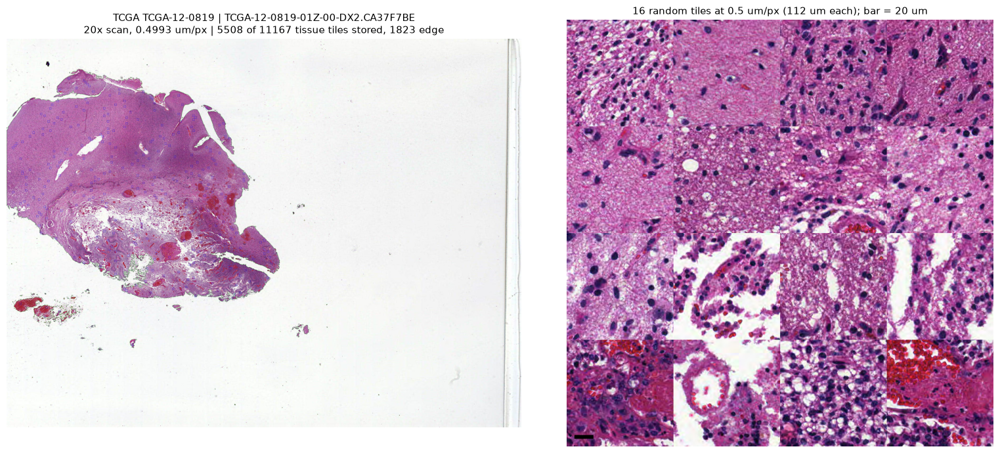

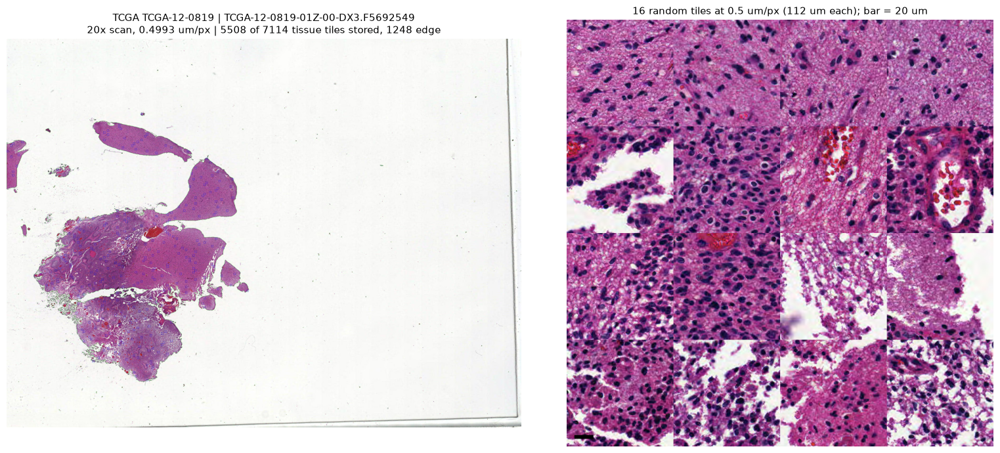

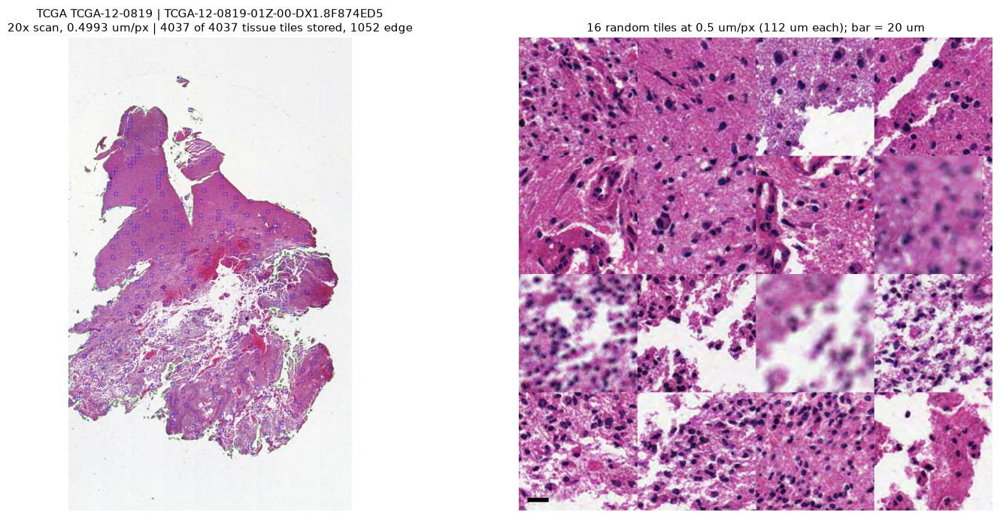

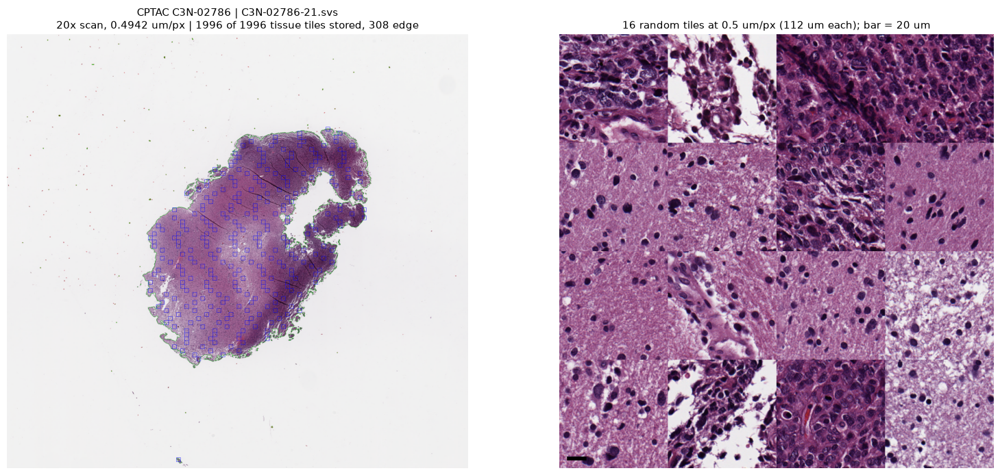

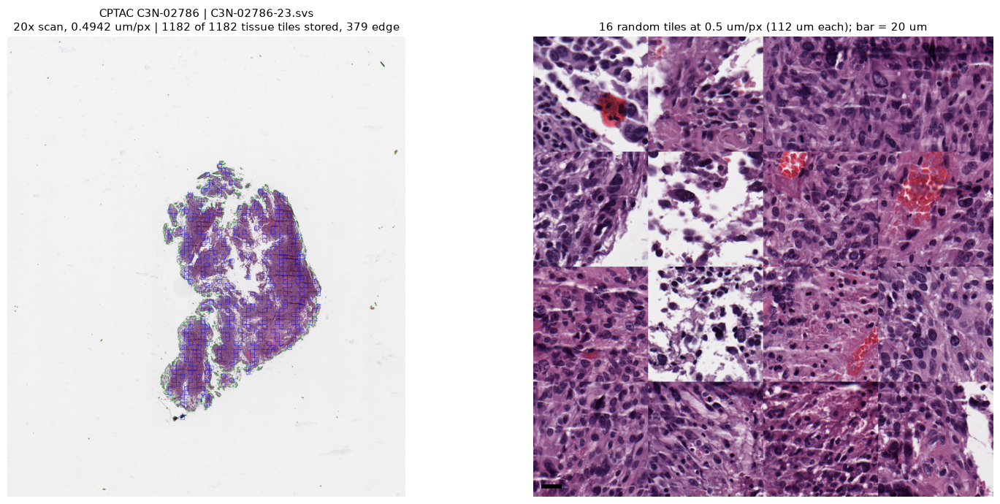

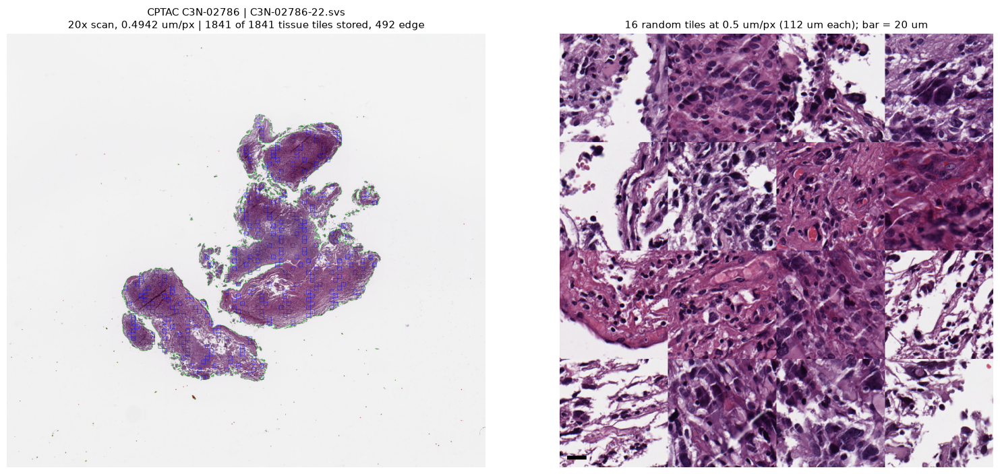

In [7]:
# Compare tiled slides: QC overview (tissue outline + a sample of stored tiles) next to a grid of random tiles.
# Each tile grid has a 20 um scale bar, so nucleus size can be compared across slides and scanners.
for key in SLIDES:
    row = find_slide(key)
    h5_path = ROOT / row.h5
    qc_image = Image.open(h5_path.with_name(h5_path.stem + "_qc.png"))
    with h5py.File(h5_path) as h5:
        attrs = dict(h5.attrs)
        n = len(h5["tiles"])
    chosen = np.random.default_rng(SEED).choice(n, size=min(GRID * GRID, n), replace=False)
    tiles = read_stored(row, sorted(chosen))

    tile_px = int(attrs["tile_px"])
    grid = np.full((GRID * tile_px, GRID * tile_px, 3), 255, dtype=np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, GRID)
        grid[r * tile_px:(r + 1) * tile_px, c * tile_px:(c + 1) * tile_px] = img
    bar_px = int(round(SCALE_BAR_UM / attrs["target_mpp"]))
    grid[-24:-16, 16:16 + bar_px] = 0   # black bar in the bottom-left tile

    scan = "40x" if attrs["source_mpp_x"] < 0.35 else "20x"
    fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 7))
    ax_qc.imshow(qc_image)
    ax_qc.set_title(f"{row.source} {row.patient_id} | {row.file_name[:32]}\n"
                    f"{scan} scan, {attrs['source_mpp_x']:.4f} um/px | {attrs['n_stored_tiles']} of "
                    f"{attrs['n_tissue_tiles']} tissue tiles stored, "
                    f"{attrs['n_edge_tiles']} edge" + (" | floor applied" if attrs["mask_floor_applied"] else ""),
                    fontsize=11)
    ax_tiles.imshow(grid)
    ax_tiles.set_title(f"{len(tiles)} random tiles at {attrs['target_mpp']} um/px "
                       f"({attrs['tile_um']:.0f} um each); bar = {SCALE_BAR_UM} um", fontsize=11)
    for ax in (ax_qc, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## A closer look at full resolution

The thumbnails above are 8–16× coarser than the tiles, too coarse to judge a pale edge or a small island. This
cell reads one grid position (`ZOOM_GRID_INDEX`) with `ZOOM_CONTEXT` tiles of context around it at 0.5 µm/px,
next to the thumbnail with the spot marked, and prints its scores from `_patches.csv`.

- Leave `ZOOM_GRID_INDEX = None` for a random **edge** tile: the borderline cases the mask leaves out.
- Or take a `grid_index` from `_patches.csv`, the worst-tiles figures or the Whole-slide view. Background
  positions (not in `_patches.csv`) work too; their coordinates come from the `.h5` grid arrays.

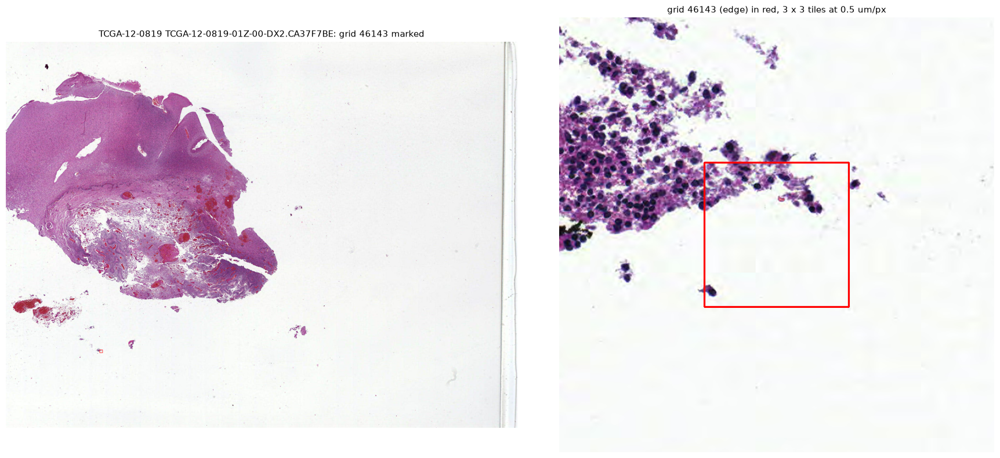

role                         edge
mask_fraction            0.107143
glass_fraction           0.747369
laplacian_variance     289.087048
near_white_fraction      0.218949
near_black_fraction           0.0
mean_r                 231.652722
mean_g                 228.808893
mean_b                 234.388612


In [8]:
# Read one grid position with some context at full resolution, next to the thumbnail with the spot marked.
ZOOM_SLIDE = SLIDES[0]   # slide ID or file-name prefix
ZOOM_GRID_INDEX = None   # a grid_index; None = a random edge tile
ZOOM_CONTEXT = 1         # tiles of context on each side (1 -> a 3 x 3 tile window)

row = find_slide(ZOOM_SLIDE)
table = patches_table(row)
if ZOOM_GRID_INDEX is None:
    edges = table[table.role == "edge"]
    pick = (edges if len(edges) else table).sample(1, random_state=SEED).iloc[0]
elif (table.grid_index == ZOOM_GRID_INDEX).any():
    pick = table[table.grid_index == ZOOM_GRID_INDEX].iloc[0]
else:   # background: not in _patches.csv
    with h5py.File(ROOT / row.h5) as h5:
        x, y = h5["grid_coords"][ZOOM_GRID_INDEX]
    pick = pd.Series({"grid_index": ZOOM_GRID_INDEX, "x_target": x, "y_target": y, "role": "background"})

px, c = CFG["tile_px"], ZOOM_CONTEXT
x, y = int(pick.x_target), int(pick.y_target)
wsi, _, _ = slides.open_slide(slide_file(row), CFG)
try:
    region = np.ascontiguousarray(wsi.read_rect(
        (x - c * px, y - c * px), ((2 * c + 1) * px,) * 2, CFG["target_mpp"], "mpp",
        coord_space="resolution", pad_mode="constant", pad_constant_values=255)[..., :3])
    thumb = np.ascontiguousarray(wsi.slide_thumbnail(CFG["mask_mpp"], "mpp")[..., :3])
    width, height = wsi.slide_dimensions(CFG["target_mpp"], "mpp")
finally:
    slides.close_slide(wsi)
cv2.rectangle(region, (c * px, c * px), ((c + 1) * px - 1, (c + 1) * px - 1), (255, 0, 0), 2)
sx, sy = thumb.shape[1] / width, thumb.shape[0] / height
marked = thumb.copy()
cv2.rectangle(marked, (int(x * sx) - 4, int(y * sy) - 4), (int((x + px) * sx) + 4, int((y + px) * sy) + 4),
              (255, 0, 0), 2)

fig, (ax_thumb, ax_region) = plt.subplots(1, 2, figsize=(18, 8))
ax_thumb.imshow(marked)
ax_thumb.set_title(f"{row.patient_id} {row.file_name[:32]}: grid {int(pick.grid_index)} marked", fontsize=11)
ax_region.imshow(region)
ax_region.set_title(f"grid {int(pick.grid_index)} ({pick.role}) in red, {2 * c + 1} x {2 * c + 1} tiles at "
                    f"{CFG['target_mpp']} um/px", fontsize=11)
for ax in (ax_thumb, ax_region):
    ax.axis("off")
plt.tight_layout()
plt.show()
scores = ["role", "mask_fraction", "glass_fraction", "laplacian_variance", "near_white_fraction",
          "near_black_fraction", "mean_r", "mean_g", "mean_b"]
print(pick[[k for k in scores if k in pick.index]].to_string())

## Checking every tile

Flags every stored tile on four measures, then shows, per slide, a contact sheet of all its tiles (flagged tiles
boxed in red, in grid order so neighbouring tiles form continuous tissue) and the 8 worst tiles for each
measure. A summary table of flag counts per slide comes last.

| Measure | Definition | Flag when | Catches | Source |
|---|---|---|---|---|
| glass | fraction of uncolored glass (saturation < 8, value > 200) | > 0.5 | background, tissue edges | `glass_fraction` |
| blur | variance of the Laplacian | < 50 | out-of-focus or featureless tiles | `laplacian_variance` |
| dark | fraction of very dark pixels (V < 60) | > 0.2 | folds, debris, ink | `dark_fraction` |
| green | fraction of green pixels | > 0.02 | green marker ink | `green_fraction` |

All four measures are read from `_patches.csv`, the scores `tile.py` saved when it read each tile (the
definitions are in `configs/tiling.yaml`), so the summary covers every tissue tile, stored or not, without
decoding anything. The contact sheets and worst-tile figures need pixels, so they show the stored tiles only.
Flags here are looser than the QC policy on purpose: they mark tiles to look at, not tiles to drop.

**How to run it on subset B**

- **Whole subset:** `CHECK_SLIDES = None`, `SHOW_FIGURES = False` gives the summary table (`flag_summary`,
  sorted by `any_flag`) from the saved scores. Fast.
- **Then a few slides:** set `CHECK_SLIDES` to the slides with the most flags, e.g.
  `flag_summary.slide_id.head(3).tolist()`, and `SHOW_FIGURES = True`. Each slide's contact sheet adds several MB
  to the notebook and can hold thousands of tiles, so keep the list short.

**Results (tiling-v7):** to fill in after the run.

In [9]:
# Check every tissue tile: flags from the saved scores, a flagged-tile summary, and per slide a contact sheet
# of all its stored tiles (flagged ones boxed in red) and the worst stored tiles per measure.
CHECK_SLIDES = None     # None = every slide in index_<SUBSET>.csv; or a list of slide IDs / file-name prefixes
THUMB_PX = 40           # size of each tile in the contact sheet
WORST_N = 8             # full-size examples shown per measure
SHOW_FIGURES = False    # True = contact sheet and worst tiles per slide (keep CHECK_SLIDES short)
FLAGS = {               # measure: (rule, limit) -- a tile is flagged when the rule holds
    "glass":  (">", 0.5),    # fraction of uncolored glass (saturation < 8, value > 200)
    "blur":   ("<", 50.0),   # variance of the Laplacian; low = out of focus or featureless
    "dark":   (">", 0.2),    # fraction of very dark pixels (folds, debris, ink)
    "green":  (">", 0.02),   # fraction of green pixels (green marker ink)
}
SAVED = {"glass": "glass_fraction", "blur": "laplacian_variance",   # measure -> _patches.csv column
         "dark": "dark_fraction", "green": "green_fraction"}
measures = list(FLAGS)
checked = index[index.n_tissue_tiles > 0]   # skip slides with no tiles
if CHECK_SLIDES is not None:
    checked = checked[checked.slide_id.isin(CHECK_SLIDES)
                      | checked.file_name.str.startswith(tuple(CHECK_SLIDES))]
    if checked.empty:
        raise ValueError(f"no slides match {CHECK_SLIDES}")
summary = []
for slide in tqdm(list(checked.itertuples()), desc="slides"):
    table = patches_table(slide)
    stats = table[table.role == "tissue"]
    if SHOW_FIGURES:   # pixels exist only for stored tiles
        stats = stats[stats.stored]
    stats = stats.sort_values("grid_index").reset_index(drop=True)   # grid order
    stats = stats.assign(**{m: stats[column] for m, column in SAVED.items()})
    smalls = []
    if SHOW_FIGURES:   # decode one tile at a time; keep only small copies
        with h5py.File(ROOT / slide.h5) as h5:
            for i in stats.h5_index.astype(int):
                img = np.asarray(Image.open(io.BytesIO(h5["tiles"][i].tobytes())))
                smalls.append(cv2.resize(img, (THUMB_PX, THUMB_PX), interpolation=cv2.INTER_AREA))
    stats["flagged_by"] = stats.apply(lambda r: [m for m in measures if (
        r[m] > FLAGS[m][1] if FLAGS[m][0] == ">" else r[m] < FLAGS[m][1])], axis=1)
    bad = stats["flagged_by"].str.len() > 0
    summary.append({"slide_id": slide.slide_id, "patient": slide.patient_id, "file": slide.file_name[:23],
                    "tiles": len(stats), "stored": slide.n_stored_tiles, "edge": slide.n_edge_tiles,
                    **{f"{m}_flagged": int(stats["flagged_by"].apply(lambda f: m in f).sum()) for m in measures},
                    "any_flag": int(bad.sum()), "median_blur": round(stats.blur.median()),
                    "mask_threshold": slide.mask_threshold})

    if not SHOW_FIGURES:
        continue

    # Contact sheet of every tile, flagged ones outlined in red.
    cols = int(np.ceil(np.sqrt(len(smalls) * 1.6)))
    rows = int(np.ceil(len(smalls) / cols))
    sheet = np.full((rows * THUMB_PX, cols * THUMB_PX, 3), 255, np.uint8)
    for k, small in enumerate(smalls):
        r, c = divmod(k, cols)
        if bad[k]:
            small = small.copy()
            cv2.rectangle(small, (0, 0), (THUMB_PX - 1, THUMB_PX - 1), (255, 0, 0), 2)
        sheet[r * THUMB_PX:(r + 1) * THUMB_PX, c * THUMB_PX:(c + 1) * THUMB_PX] = small
    plt.figure(figsize=(20, 20 * rows / cols))
    plt.imshow(sheet)
    plt.title(f"{slide.source} {slide.patient_id} {slide.file_name[:23]}: all {len(smalls)} tiles, "
              f"{int(bad.sum())} flagged (red)", fontsize=13)
    plt.axis("off")
    plt.show()

    # The worst tiles for each measure, full size, with their values.
    fig, axes = plt.subplots(len(measures), WORST_N, figsize=(2.2 * WORST_N, 2.5 * len(measures)), squeeze=False)
    for ax_row, m in zip(axes, measures):
        order = stats[m].sort_values(ascending=(FLAGS[m][0] == "<")).index[:WORST_N]
        for ax in ax_row:
            ax.axis("off")
        for ax, k, img in zip(ax_row, order, read_stored(slide, stats.h5_index[order])):
            hit = m in stats.at[k, "flagged_by"]
            ax.imshow(img)
            ax.set_title(f"{m} {stats.at[k, m]:.2f}" + (" *" if hit else "") + f"\ngrid {stats.at[k, 'grid_index']}",
                         fontsize=9, color="red" if hit else "black")
    fig.suptitle(f"{slide.patient_id}: worst {WORST_N} tiles per measure (* = past the flag limit)", fontsize=12)
    plt.tight_layout()
    plt.show()

flag_summary = pd.DataFrame(summary).sort_values("any_flag", ascending=False)
display(flag_summary)

slides:   0%|          | 0/6 [00:00<?, ?it/s]

,slide_id,patient,file,tiles,stored,edge,glass_flagged,blur_flagged,dark_flagged,green_flagged,any_flag,median_blur,mask_threshold
5,f520937e-b280-43dc-8c43-4f3a77aff298,TCGA-12-0819,TCGA-12-0819-01Z-00-DX1,4037,4037,1052,4,71,0,0,75,535,41.0
0,C3N-02786-21,C3N-02786,C3N-02786-21.svs,1996,1996,308,1,0,68,0,69,712,31.0
1,C3N-02786-22,C3N-02786,C3N-02786-22.svs,1841,1841,492,11,0,15,0,26,709,31.0
2,C3N-02786-23,C3N-02786,C3N-02786-23.svs,1182,1182,379,3,0,3,0,6,452,26.0
3,01116270-bf0e-44c1-bd77-033592e2a3e4,TCGA-12-0819,TCGA-12-0819-01Z-00-DX2,11167,5508,1823,3,3,3,0,6,841,46.0
4,0148b9eb-68fe-4924-a4fb-b4508c21a1b4,TCGA-12-0819,TCGA-12-0819-01Z-00-DX3,7114,5508,1248,0,1,1,0,2,806,46.0


## QC decisions by reason

`tile.py` scores every tissue and edge tile; `data_prep/qc.py` then applies `configs/qc_policy.yaml` and gives
each one a decision: **reject** (glass fraction above `max_glass_fraction`, nearly all near-white or near-black,
or a blur score below `blur_reject_below`), **review** (blur score below `blur_review_below`, very dark, or any
other review rule the team turns on) or **accept**. Edge tiles are never accepted automatically: the rules can
reject them and the rest go to review (reason `edge`), so a reviewer can reinstate one; they are counted
separately from tissue tiles. This section
replaces the tiling-v6 "Dropped tiles" section: nothing is dropped during tiling any more, and the decisions
can be changed without re-tiling.

This cell lists every slide with rejected or review tissue tiles, sorted by their share, then shows up to
`MAX_SHOWN` stored tissue tiles for each reason on the `TOP_N` worst slides (or on `DECISION_SLIDES`). Every tissue tile
gets a decision, stored or not; with a cap, the examples come from the stored ones. Run
`python data_prep/qc.py --root <ROOT> --subset <SUBSET>` first.

**Results (tiling-v7, policy qc-v1):** to fill in after the run.

In [ ]:
# QC decisions from qc.py: per-slide counts, then sample tiles for each reject / review reason.
DECISION_SLIDES = None   # None = the TOP_N slides with the highest share rejected or sent to review
TOP_N = 8                # slides shown when DECISION_SLIDES is None
MAX_SHOWN = 8            # tiles shown per reason per slide (random sample)

decided = TILED / "qc" / POLICY["version"]
if not (decided / f"slides_{SUBSET}.csv").exists():
    print(f"No QC decisions for policy {POLICY['version']} yet. Run:\n"
          f"python data_prep/qc.py --root {ROOT} --subset {SUBSET}")
else:
    counts = pd.read_csv(decided / f"slides_{SUBSET}.csv").merge(index[["slide_id", "file_name"]], on="slide_id")
    counts["flagged_pct"] = (100 * (counts.reject + counts.review) / counts.tissue_tiles.clip(lower=1)).round(1)
    flagged = counts[counts.reject + counts.review > 0].sort_values("flagged_pct", ascending=False)
    print(f"Policy {POLICY['version']}: tissue tiles {counts.accept.sum():,} accept, {counts.review.sum():,} review, "
          f"{counts.reject.sum():,} reject; {len(flagged)} of {len(counts)} slides have flagged tissue tiles")
    print(f"Edge tiles: {counts.edge_review.sum():,} review, {counts.edge_reject.sum():,} reject "
          f"(only a reviewer's accept puts one in the model)")
    display(flagged.assign(file_name=flagged.file_name.str[:23])[
        ["source", "patient_id", "file_name", "tissue_tiles", "accept", "review", "reject", "flagged_pct", "reasons"]])

    if DECISION_SLIDES is None:
        show = flagged.head(TOP_N)
    else:
        show = flagged[flagged.slide_id.isin(DECISION_SLIDES)
                       | flagged.file_name.str.startswith(tuple(DECISION_SLIDES))]
        if show.empty:
            raise ValueError(f"no slides with flagged tiles match {DECISION_SLIDES}")

    for slide in show.itertuples():
        row = index[index.slide_id == slide.slide_id].iloc[0]
        decisions = pd.read_csv(ROOT / slide.decisions).query("role == 'tissue'").merge(
            patches_table(row)[["patch_id", "glass_fraction", "laplacian_variance", "mean_r", "mean_g", "mean_b"]],
            on="patch_id")
        reasons = sorted({r for rs in decisions.reasons for r in rs.split(";")} - {"pass"})
        fig, axes = plt.subplots(len(reasons), MAX_SHOWN, figsize=(2.2 * MAX_SHOWN, 2.8 * len(reasons)),
                                 squeeze=False)
        for ax_row, reason in zip(axes, reasons):
            hits = decisions[decisions.stored & decisions.reasons.str.split(";").apply(lambda rs: reason in rs)]
            pick = hits.sample(min(MAX_SHOWN, len(hits)), random_state=SEED).sort_values("h5_index")
            for ax in ax_row:
                ax.axis("off")
            for ax, (_, d), img in zip(ax_row, pick.iterrows(), read_stored(row, pick.h5_index)):
                ax.imshow(img)
                ax.set_title(f"{d.decision}: {d.reasons.replace(';', ', ')}\n"
                             f"glass {d.glass_fraction:.2f}, blur {d.laplacian_variance:.0f}",
                             fontsize=8, color="red" if d.decision == "reject" else "darkorange")
        fig.suptitle(f"{row.patient_id} {row.file_name[:23]}: {slide.reject} reject, {slide.review} review "
                     f"of {slide.tissue_tiles} ({slide.flagged_pct}%)", fontsize=11)
        plt.tight_layout()
        plt.show()

## Rereading a tile from the slide

Edge tiles are scored but not stored, and any stored tile can be checked against the slide. For one slide
(`REREAD_SLIDE`), this cell rereads a random edge tile, a random tissue tile outside the stored sample (if the
slide was capped) and a random stored tissue tile from the `.svs` at their saved 0.5 µm/px coordinates, and compares the SHA-256 of the pixels with the hash `tile.py` recorded when it
first read them. For the tissue tile it also shows the stored PNG next to the reread.

A matching hash means the coordinates in `_patches.csv` and the `.h5` point to exactly the pixels that were
scored and stored, so any tile can be recreated later without re-tiling. It needs the slide's `.svs` under
`ROOT/raw/`.

edge tile, grid 46143 at (11424, 37408): reread pixels match the recorded hash
tissue, not stored tile, grid 20731 at (6944, 16800): reread pixels match the recorded hash
tissue, stored tile, grid 37651 at (25760, 30464): reread pixels match the recorded hash
  stored PNG equals the reread


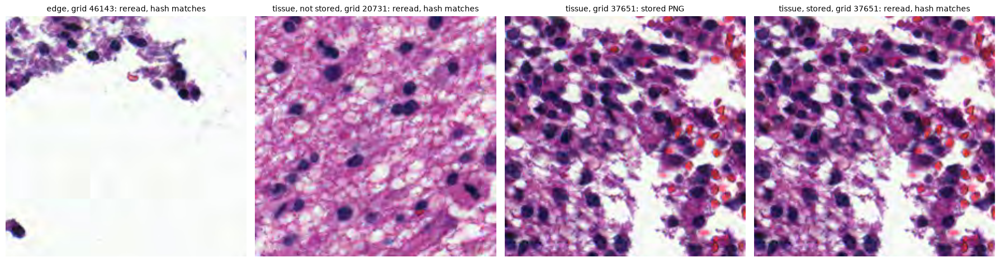

In [11]:
# Reread an edge tile (scored, not stored) and a stored tissue tile from the slide; compare the pixel hashes.
REREAD_SLIDE = SLIDES[0]   # slide ID or file-name prefix

row = find_slide(REREAD_SLIDE)
table = patches_table(row)
tissue = table.role == "tissue"
picks = [part.sample(1, random_state=SEED).iloc[0]
         for part in (table[table.role == "edge"], table[tissue & ~table.stored], table[tissue & table.stored])
         if len(part)]
wsi, _, _ = slides.open_slide(slide_file(row), CFG)
try:
    reread = [np.ascontiguousarray(wsi.read_rect((int(p.x_target), int(p.y_target)), (CFG["tile_px"],) * 2,
                                                 CFG["target_mpp"], "mpp", coord_space="resolution")[..., :3])
              for p in picks]
finally:
    slides.close_slide(wsi)

panels = []
for p, img in zip(picks, reread):
    same = hashlib.sha256(img.tobytes()).hexdigest() == p.pixel_sha256
    kind = p.role if p.role == "edge" else ("tissue, stored" if p.stored else "tissue, not stored")
    print(f"{kind} tile, grid {p.grid_index} at ({p.x_target}, {p.y_target}): reread pixels "
          f"{'match' if same else 'DO NOT match'} the recorded hash")
    if p.role == "tissue" and p.stored:
        stored = read_stored(row, [p.h5_index])[0]
        print(f"  stored PNG {'equals' if np.array_equal(stored, img) else 'DIFFERS FROM'} the reread")
        panels.append((stored, f"tissue, grid {p.grid_index}: stored PNG"))
    panels.append((img, f"{kind}, grid {p.grid_index}: reread, hash {'matches' if same else 'differs'}"))

fig, axes = plt.subplots(1, len(panels), figsize=(4.5 * len(panels), 4.8), squeeze=False)
for ax, (img, title) in zip(axes[0], panels):
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Whole-slide view

For each slide in `VIEW_SLIDES`: the full slide at `THUMB_MPP` next to the same thumbnail with **every** grid tile
that touches the mask: stored tissue tiles in blue, tissue tiles outside a capped sample in cyan, edge tiles
(scored, not stored) in yellow. If `qc.py` has
been run, tissue tiles it rejected are red and tiles sent to review are magenta. Unlike the QC overview, which
outlines at most 300 tiles, nothing is left out here.

**Results (tiling-v7):** to fill in after the run. Good slides to view: those with the floor applied, and the
slides with the most flagged tiles in the sections above.

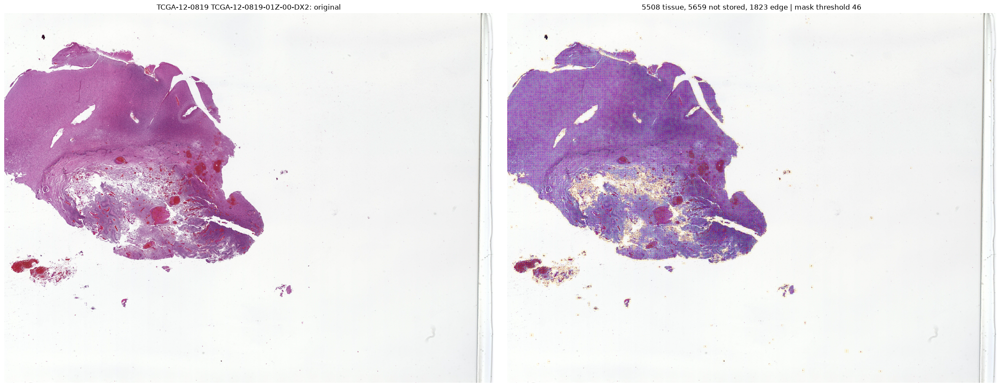

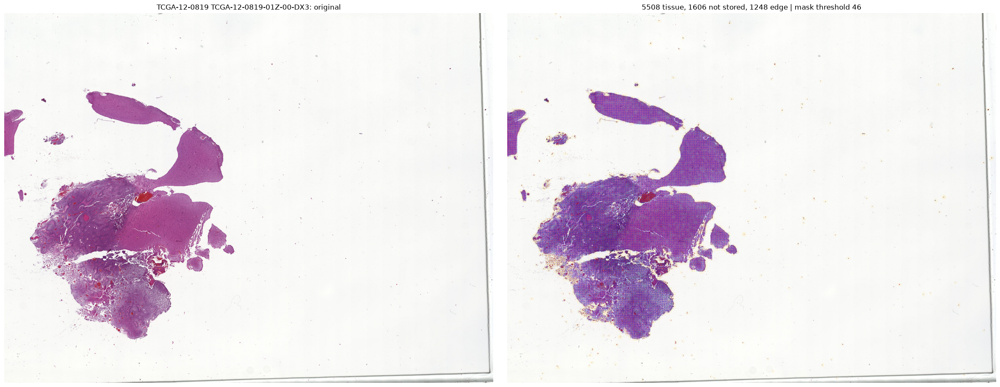

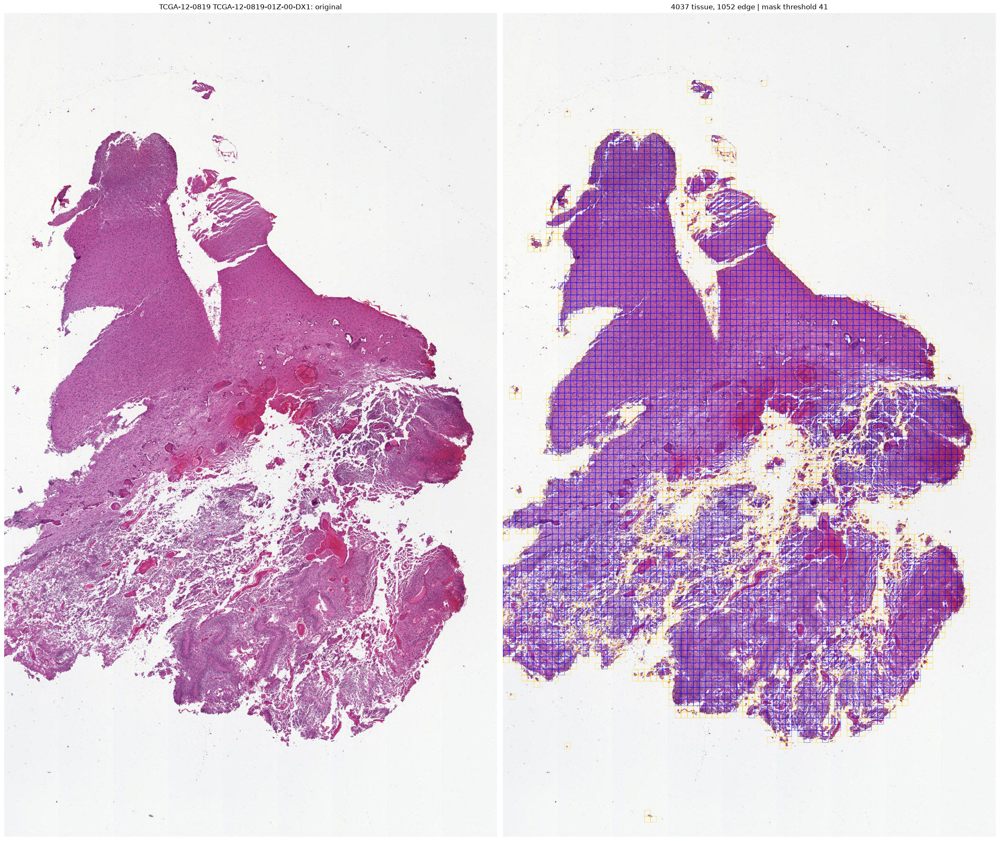

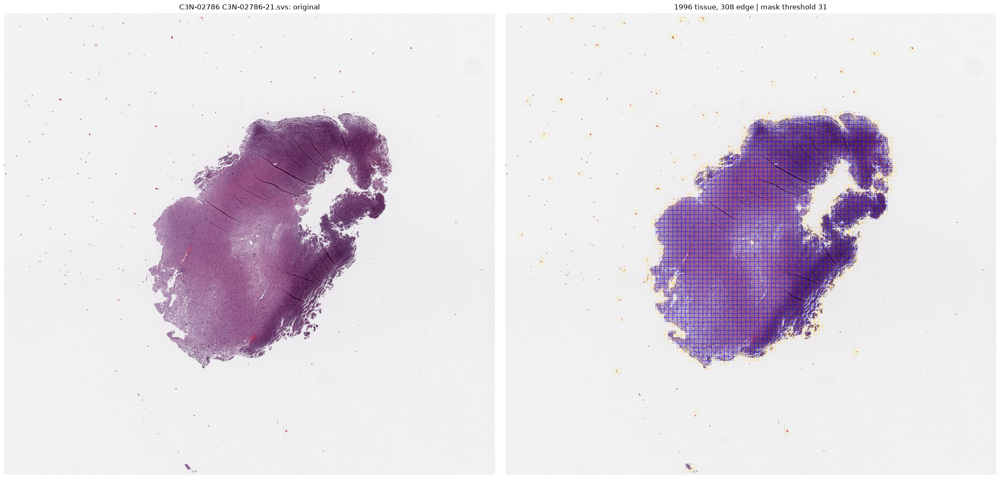

In [12]:
# Whole-slide view: the original thumbnail next to the same thumbnail with every tile that touches the mask:
# stored tissue (blue), tissue outside a capped sample (cyan), edge (yellow), and the QC policy's reject (red)
# and review (magenta) if qc.py has been run.
VIEW_SLIDES = SLIDES[:4]   # slide IDs or file-name prefixes
THUMB_MPP = 4.0            # thumbnail resolution in um/px (lower = sharper and bigger)
COLORS = {"tissue": (0, 0, 255), "not stored": (0, 200, 255), "edge": (255, 200, 0),
          "review": (255, 0, 255), "reject": (255, 0, 0)}

for key in VIEW_SLIDES:
    row = find_slide(key)
    with h5py.File(ROOT / row.h5) as h5:
        attrs = dict(h5.attrs)
        grid, roles, in_h5 = h5["grid_coords"][:], h5["grid_role"][:], h5["grid_h5_index"][:]
    decided = TILED / "qc" / POLICY["version"] / row.source / row.patient_id / f"{row.slide_id}_decisions.csv"
    decision = {}
    if decided.exists():
        d = pd.read_csv(decided)
        decision = dict(zip(d.grid_index, d.decision))

    wsi, _, _ = slides.open_slide(slide_file(row), CFG)
    try:
        original = np.ascontiguousarray(wsi.slide_thumbnail(THUMB_MPP, "mpp")[..., :3])
    finally:
        slides.close_slide(wsi)
    overlay = original.copy()
    scale = attrs["target_mpp"] / THUMB_MPP             # tile coords are at target_mpp
    size = int(round(attrs["tile_px"] * scale))
    shown = {name: 0 for name in COLORS}
    for g in np.flatnonzero(roles > 0):
        name = "edge" if roles[g] == slides.ROLE_CODES["edge"] else decision.get(g, "tissue")
        if name in ("accept", "tissue"):
            name = "tissue" if in_h5[g] >= 0 else "not stored"
        shown[name] += 1
        x, y = (grid[g] * scale).round().astype(int)
        cv2.rectangle(overlay, (x, y), (x + size - 1, y + size - 1), COLORS[name], 1)

    height, width = original.shape[:2]
    fig, (ax_orig, ax_tiles) = plt.subplots(1, 2, figsize=(24, 12 * height / width))
    ax_orig.imshow(original)
    ax_orig.set_title(f"{row.patient_id} {row.file_name[:23]}: original", fontsize=12)
    ax_tiles.imshow(overlay)
    ax_tiles.set_title(", ".join(f"{n} {name}" for name, n in shown.items() if n) +
                       f" | mask threshold {attrs['mask_threshold']:.0f}" +
                       (" (floor applied)" if attrs["mask_floor_applied"] else ""), fontsize=12)
    for ax in (ax_orig, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Integrity audit

The rerun check in `tile.py` only compares file sizes. `tile.py --audit` recomputes each slide's `.h5` and
`_patches.csv` SHA-256 against its receipt and checks every stored tile's pixel hash, and saves the result.
This cell shows the latest audit for this config version and subset, warns if any slide was tiled after it,
and lists slides with errors. Run the audit after the full run and before training.

In [13]:
# The latest saved audit for this config version and subset.
audits = sorted((ROOT / "state" / "tiling" / CFG["version"]).glob(f"audit_{SUBSET}_*.json"))
if not audits:
    print(f"No audit yet. Run:\npython data_prep/tile.py --root {ROOT} --subset {SUBSET} --audit")
else:
    report = json.loads(audits[-1].read_text())
    print(f"{audits[-1].name}: {report['slides_audited']} of {report['slides_selected']} selected slides audited, "
          f"{report['tiles_checked']:,} tiles checked, {report['slides_with_errors']} slides with errors"
          + ("" if report["complete"] else " (interrupted)"))
    later = index[index.tiled_at_utc > report["audited_at_utc"]]
    if len(later):
        print(f"WARNING: {len(later)} slides were tiled after this audit; run it again")
    errors = [s for s in report["slides"] if s["n_errors"]]
    if errors:
        display(pd.DataFrame(errors)[["source", "patient_id", "slide_id", "tiles_checked", "n_errors", "errors"]])

audit_B_20261108_235739.json: 6 of 259 selected slides audited, 20,072 tiles checked, 0 slides with errors


## Matched coordinates with gbm_patching.py

Both tilers use TIAToolbox's grid at 224 px and 0.5 µm/px and the same patch IDs
(`<source>_<16 hex of SHA-256(slide_id)>_<x>_<y>`), so the two halves can be compared tile by tile. Set
`OTHER_MANIFEST` to the `patch_manifest.csv` that `gbm_patching.py` wrote for one slide (under
`<output>/slides/<slide_key>/attempt_*/`), copied to this machine. The cell then reports:

- whether the pixels are identical wherever both read the same tile (pixel hashes),
- the largest difference in each shared score (mean RGB, Laplacian variance, near-white, near-black),
- how this tiler's roles (tissue / edge / background) line up with that script's decisions. The two masks are
  still different (median 7 vs 5, two-class vs three-class Otsu, no floor or closing there), so some
  disagreement is expected; this table is where it shows.

In [14]:
# Compare this tiler with the team's gbm_patching.py on one slide, tile by tile, matched by patch ID.
OTHER_MANIFEST = None   # e.g. Path("~/Downloads/patch_manifest.csv").expanduser()

if OTHER_MANIFEST is None:
    print("Set OTHER_MANIFEST to a gbm_patching.py patch_manifest.csv for a slide tiled here.")
else:
    other = pd.read_csv(OTHER_MANIFEST, dtype={"pixel_sha256": str, "decision": str, "reasons": str})
    row = index[index.slide_id == other.slide_id.iloc[0]].iloc[0]
    ours = patches_table(row)
    both = ours.merge(other, on="patch_id", suffixes=("", "_other"))
    read_by_both = both[both.pixel_sha256_other.notna()]
    same = (read_by_both.pixel_sha256 == read_by_both.pixel_sha256_other).sum()
    print(f"{row.patient_id} {row.file_name[:32]}: {len(read_by_both)} tiles read by both, "
          f"{same} with identical pixels")
    shared = ["mean_r", "mean_g", "mean_b", "gray_median", "laplacian_variance",
              "near_white_fraction", "near_black_fraction"]
    print("Largest score difference:", {k: float((read_by_both[k] - read_by_both[k + "_other"]).abs().max())
                                        for k in shared})
    roles = other[["patch_id", "decision", "reasons"]].merge(ours[["patch_id", "role"]], on="patch_id", how="left")
    roles["role"] = roles.role.fillna("background")
    roles["their_primary_reason"] = roles.reasons.str.split(";").str[0]
    display(pd.crosstab([roles.decision, roles.their_primary_reason], roles.role, margins=True))

Set OTHER_MANIFEST to a gbm_patching.py patch_manifest.csv for a slide tiled here.


## Recording reviews

Reviews are kept apart from the tiling outputs, in CSVs under `ROOT/review/<version>/`, through `review.py`.
Nothing is edited in place: each call appends a record, and the latest record for a tile or slide wins.
`export.py` applies them on top of the QC decisions, in this order: QC decision → artifact region → patch
review → slide exclusion.

- **Patch review:** accept, reject or review one tile by its `patch_id` (from `_patches.csv`, the figures
  above or the zoom cell), with a defect type. Accepting an edge tile reinstates it (the loader rereads it
  from the slide).
- **Artifact region:** a level-0 box `(x0, y0, x1, y1)` around a fold, pen mark or scanner artifact; every
  tissue tile it touches is rejected (or sent to review). The Whole-slide view and the zoom cell give
  coordinates.
- **Slide sign-off:** approve a slide, recording what was checked (mask, focus, pale, background, artifacts),
  or exclude it with a reason. Sign-off is required for every slide only if the policy sets
  `require_signoff: true`. Excluding a slide counts it as accounted for, so its patient is not blocked.

Defect types are technical damage only: necrosis, hemorrhage, microvascular proliferation and low cellularity
are tissue, not defects. Keep MGMT labels out of review. Fill in the fields and set `SAVE = True` to record;
the cell then shows the current records.

In [15]:
# Record a review, then show the current review records for this tiling version.
print("Defect types:", sorted(review.DEFECTS))
SAVE = False                       # True = append the record(s) filled in below
REVIEWER = ""                      # your name

PATCH_ID, PATCH_DECISION, PATCH_DEFECT, PATCH_NOTES = "", "reject", "other", ""
REGION_SLIDE, REGION_BOX, REGION_DECISION, REGION_DEFECT = "", None, "reject", "other"   # box: (x0, y0, x1, y1)
SIGNOFF_SLIDE, SIGNOFF_DECISION, SIGNOFF_NOTES = "", "approve", ""     # exclude needs notes
SIGNOFF_CHECKS = dict(mask=False, focus=False, pale=False, background=False, artifacts=False)

if SAVE:
    if not REVIEWER.strip():
        raise ValueError("Set REVIEWER")
    if PATCH_ID:
        review.append_patch_review(ROOT, VERSION, PATCH_ID, PATCH_DECISION, REVIEWER, PATCH_DEFECT, PATCH_NOTES)
        print("Recorded patch review:", PATCH_ID, PATCH_DECISION)
    if REGION_SLIDE and REGION_BOX:
        slide = find_slide(REGION_SLIDE)
        review.append_region(ROOT, VERSION, slide.source, slide.slide_id, REGION_BOX, REGION_DECISION,
                             REVIEWER, REGION_DEFECT)
        print("Recorded region on", slide.file_name)
    if SIGNOFF_SLIDE:
        slide = find_slide(SIGNOFF_SLIDE)
        review.sign_off_slide(ROOT, VERSION, slide.source, slide.slide_id, SIGNOFF_DECISION, REVIEWER,
                              SIGNOFF_NOTES, **SIGNOFF_CHECKS)
        print("Recorded sign-off:", slide.file_name, SIGNOFF_DECISION)

for path in review.review_files(ROOT, VERSION):
    records = pd.read_csv(path)
    print(f"{path.name}: {len(records)} records")
    display(records.tail(10))
if not review.review_files(ROOT, VERSION):
    print("No review records yet.")

Defect types: ['background', 'blur', 'bubble', 'exposure', 'fold', 'missing_tile', 'none', 'other', 'pen', 'scanner_stripe', 'stitching_seam', 'tear', 'very_dark']
No review records yet.


## Export summary

`export.py` builds the model input from the QC decisions and the reviews. A tile reaches
`modeling_patches.csv` only if its slide was tiled with the current config and passed the latest audit, the QC
policy is frozen, its decision after review is accept, and its patient is in the shared fold map with every
slide accounted for (exported, or excluded at sign-off). A patient with a missing, failed or unaudited slide is
blocked on its own, without blocking anyone else.

Run it (with a frozen policy) after tiling, auditing and QC:

```
python data_prep/export.py --root <ROOT> --subset <SUBSET>
```

This cell shows the latest export for this config, policy and subset: counts, blocked patients and why, empty
bags, and tiles per role for one fold (`FOLD`). With `stored_tiles_only` (the policy default), accepted tiles
beyond the tiling cap are counted (`accepted_not_stored`) but left out, so training needs only stored tiles; edge
tiles a reviewer accepted are included and `package.py` stores them. It also says whether the export is complete
(no blocked patients) and current: `loader.load_modeling` refuses an export whose recorded inputs (reviews,
audits, QC decisions, fold map) have changed since, so rerun `export.py` after recording reviews. To train on
another machine, package the export (`python data_prep/package.py --export <export> --out <new folder>`) and
join the halves with `combine.py`.

In [ ]:
# The latest export for this tiling version, QC policy and subset.
EXPORT_POLICY = POLICY["version"]   # which policy's exports to show
FOLD = 0                            # validation fold for the role counts

exports = sorted((TILED / "export" / EXPORT_POLICY).glob(f"{SUBSET}_*"))
if not exports:
    print(f"No export yet for policy {EXPORT_POLICY}. Freeze the policy, then run:\n"
          f"python data_prep/export.py --root {ROOT} --subset {SUBSET}")
else:
    out = exports[-1]
    settings = json.loads((out / "export_settings.json").read_text())
    print(f"{out.name}: {json.dumps(settings['counts'])}")
    patients = pd.read_csv(out / "patient_index.csv")
    blocked = patients[~patients.included]
    print(f"{len(blocked)} blocked patients:")
    display(blocked[["source", "patient_id", "expected_slides", "exported_slides", "blocked_reasons"]])
    print("Empty bags:", patients[patients.empty_bag].patient_id.tolist())
    changes = loader.stale_inputs(out)
    print("Export is current" if not changes else
          f"STALE ({len(changes)} inputs changed since, e.g. {changes[0]}): rerun export.py before training")
    print("Complete: every patient accounted for" if settings.get("complete") else
          "INCOMPLETE: some patients are blocked (a preview; package.py and the loader need --allow-partial)")
    tiles = loader.with_roles(loader.load_modeling(out, check=False), FOLD)
    display(tiles.groupby("role").agg(patients=("patient_id", "nunique"), tiles=("patch_id", "size"),
                                      stored=("stored", "sum")))

## Findings and next steps (tiling-v7, subset B)

To fill in after the tiling-v7 run. The tiling-v6 findings are in the History section below; points to recheck
with v7:

1. Slides where the floor is applied, and TCGA-19-1389 DX1 (no tissue tiles in tiling-v6).
2. Blur: tiling-v6 proposed 20. In tiling-v7 the QC policy has two cutoffs, pilot values: reject below 50,
   review below 100 (to be confirmed on Couger's labeled calibration set before freezing).
3. Dark and green totals (pen marks), from Checking every tile (now saved for every tile).
4. Storage and time for the full subset, from Slides at a glance. With the cap at 5,508 tissue tiles per slide
   and PNG level 6, subset B is projected at about 100 GB; storing every tile would be about 230 GB.
5. Matched-coordinate comparison with Carlos's half.

## History: tiling-v6 and earlier

The cells below are this notebook's tiling-v6 sections, kept unchanged with their outputs as the record of those
results. They read tiling-v6 outputs (`patches/index_B.csv`, JPEG tiles, `n_sampled`, `dropped_coords`) and call
tile.py v6 functions (`tissue_grid`, `tile_quality`), so **they do not run** against tiling-v7 outputs or the
current `tile.py`. To rerun one, check out the tiling-v6 commit (`3c106a7`).

### Before the saturation mask (tiling-v2)

The tiling-v2 files were overwritten by the tiling-v3 run, so this cell rebuilds the tiles in memory instead
of reading them. It uses the current `tile.py` with `mask_method: otsu_gray`, which is the same mask, grid
and seeds as tiling-v2, so it reproduces the same 2,000 sampled tiles and the same 16 shown by the
comparison cell. Nothing is written. It needs the slide's `.svs` file under `ROOT/raw/` and imports
`tile.py` from the repo. `BEFORE_QC` is the copy of the tiling-v2 QC image saved before rerunning.

**Result:** the rebuild reports 8,617 tissue tiles for TCGA-12-0819, matching the tiling-v2 run, and the
blank beige tile (second row, first column) is back. It comes from the slide/coverslip edge, which the
grayscale mask outlined as tissue (the green line on the right of the QC image).

In [17]:
# BEFORE the saturation mask: rebuild the 16 random tiles the comparison cell showed under tiling-v2
# (grayscale Otsu), in memory without touching any files, next to the copied tiling-v2 QC image.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SLIDE = "TCGA-12-0819-01Z-00-DX2"   # slide ID or file-name prefix
BEFORE_QC = Path("~/Desktop/qc_otsu/01116270-bf0e-44c1-bd77-033592e2a3e4_qc.png").expanduser()
GRID = 4
SEED = 0                            # same SEED as the comparison cell -> same 16 tiles

# tiling-v2 = current settings with the grayscale Otsu mask.
cfg = {**tile.load_config(REPO / "configs" / "tiling.yaml")[0], "mask_method": "otsu_gray"}
_, manifest = load_manifest(tile.DEFAULT_MANIFEST)
row = next(r for r in manifest["files"] if r["slide_id"] == SLIDE or r["file_name"].startswith(SLIDE))

wsi = WSIReader.open(paths_for(ROOT, row)[0])
_, _, _, _, extractor = tile.tissue_grid(wsi, cfg)
n_tissue = len(extractor.coordinate_list)

# Same sampling as tile.py's tile_slide, then the same 16-tile pick as the comparison cell.
seed = int.from_bytes(hashlib.sha256(f"{cfg['seed']}|{row['slide_id']}".encode()).digest()[:8], "big")
count = min(n_tissue, cfg["max_tiles_per_slide"])
chosen = np.sort(np.random.default_rng(seed).choice(n_tissue, size=count, replace=False))
shown = sorted(np.random.default_rng(SEED).choice(count, size=min(GRID * GRID, count), replace=False))
tiles = [extractor[int(chosen[i])][..., :3] for i in shown]

px = cfg["tile_px"]
grid = np.full((GRID * px, GRID * px, 3), 255, dtype=np.uint8)
for k, t in enumerate(tiles):
    r, c = divmod(k, GRID)
    grid[r * px:(r + 1) * px, c * px:(c + 1) * px] = t

fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 8))
if BEFORE_QC.exists():
    ax_qc.imshow(Image.open(BEFORE_QC))
    ax_qc.set_title(f"BEFORE QC copy: {BEFORE_QC.name}", fontsize=11)
ax_qc.axis("off")
ax_tiles.imshow(grid)
ax_tiles.set_title(f"BEFORE (grayscale Otsu, tiling-v2): {row['patient_id']}\n"
                   f"16 of {count} sampled tiles ({n_tissue} tissue tiles)", fontsize=11)
ax_tiles.axis("off")
plt.tight_layout()
plt.show()

NameError: name 'tile' is not defined

### Tile scale and appearance (tiling-v6)

For each slide in `SLIDES` (10 random slides from Settings): the QC overview (tissue outline in green,
sampled tiles in blue) next to 16 random tiles, with a 20 µm scale bar on the bottom-left tile.

**What to check**

- **Scale:** nuclei and red blood cells (about 7 µm) should be the same size relative to the bar on every
  slide, 40× and 20×, TCGA and CPTAC. That confirms the resampling to 0.5 µm/px.
- **Coverage:** the blue tiles should sit on tissue, not on glass, the slide edge, pen marks or bubbles.
- **Gaps:** tissue inside the green outline with no blue tiles is either beyond the 2000-tile cap or
  removed by the quality filter (see the dropped-tiles section).

**Results (tiling-v5, 10 random slides, `SEED = 2026`; unchanged in tiling-v6, since none of these slides has an Otsu cut below 8)**

Slides: C3N-02185, C3N-02256, C3N-02769, TCGA-06-0122 DX3, TCGA-06-0169 DX1, TCGA-12-0670 DX1,
TCGA-12-1599 DX2, TCGA-14-1794 DX1, TCGA-15-1446 DX2 (40×), TCGA-27-1830 DX3.

- Scale is consistent: nuclei are the same size relative to the bar on the 40× slide and the 20× slides,
  in both cohorts.
- Coverage: on all 10 slides the blue tiles sit on tissue, with none on glass, slide edges or pen marks.
- 9 of the 10 slides dropped no tiles; TCGA-12-1599 dropped 8.
- Stain differs by cohort: CPTAC tiles are darker and more purple, TCGA tiles pinker. Worth stain
  augmentation or normalization in training.
- Some tiles are mostly blood (TCGA-15-1446, TCGA-27-1830), and a few cross a dark fold or fiber
  (TCGA-15-1446, C3N-02769). These are real slide content, not mask errors.
- None of the 10 is one of the problem slides found by the checks below; a random sample of 10 misses them.

**Pilot results (tiling-v3, 6 pilot slides, compared with tiling-v2)**

- Scale is consistent across 40× and 20× slides and across both cohorts.
- TCGA-14-0817: tissue tiles went from 2,408 to 3,122; the pale band at the top and most of the pale
  top-left section are now tiled.
- TCGA-12-0819: the slide-edge strip is no longer outlined or tiled (8,617 → 8,557 tissue tiles).
- TCGA-19-2625 (all pale): fully captured (5,885 → 6,061); faint dust specks are outlined but not tiled.
- CPTAC slides: essentially unchanged (C3N-01192-21: 1,724 → 1,769; C3N-02786-23: 864 → 913).

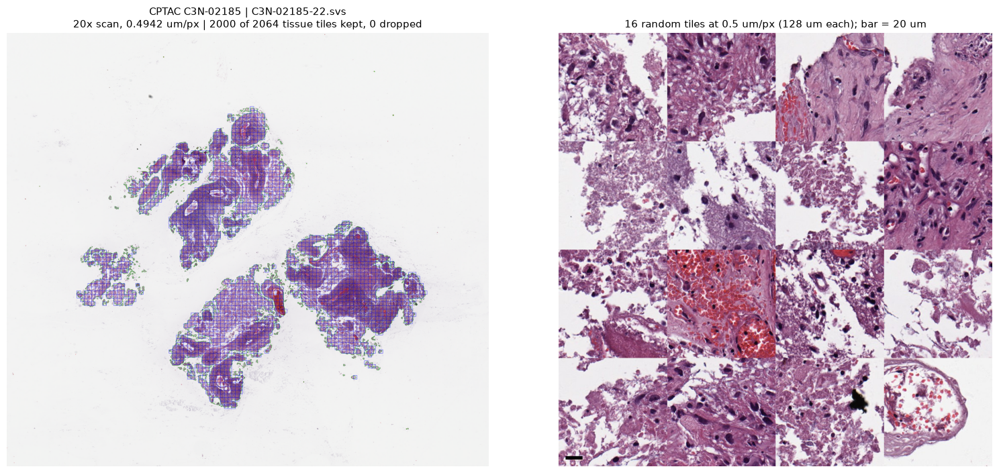

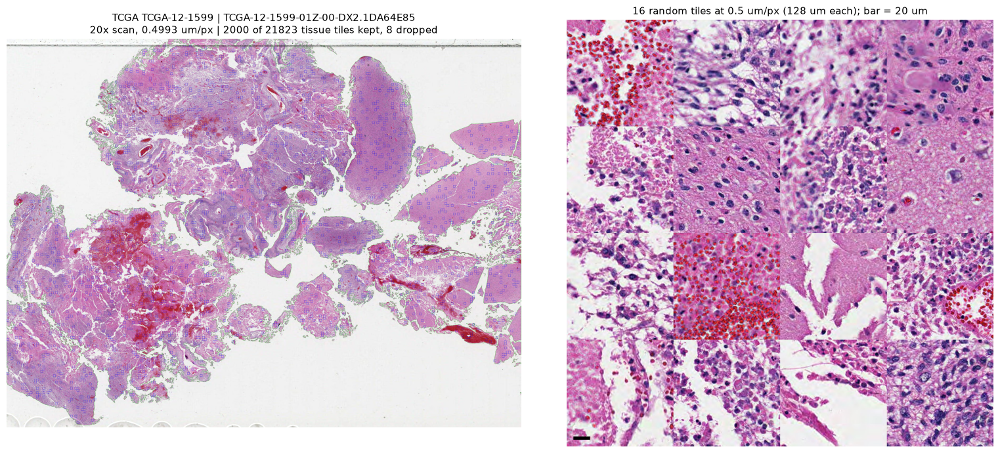

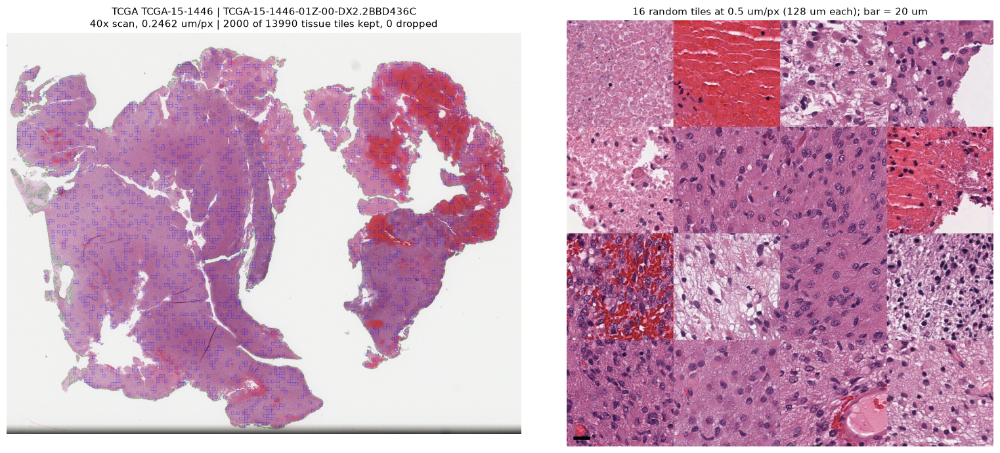

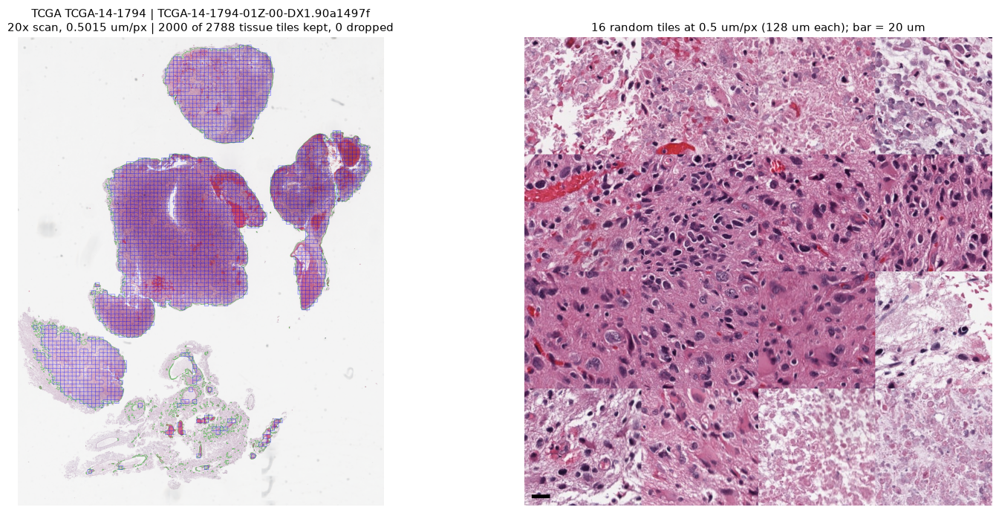

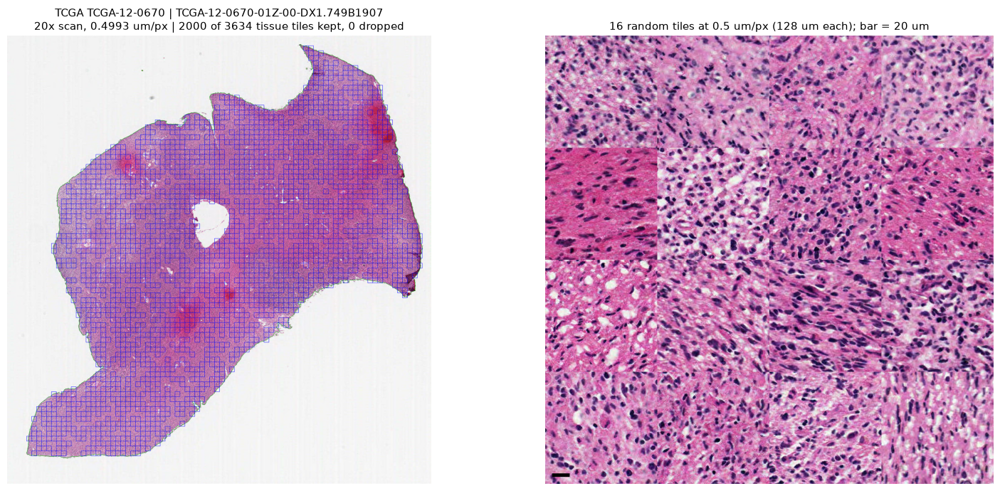

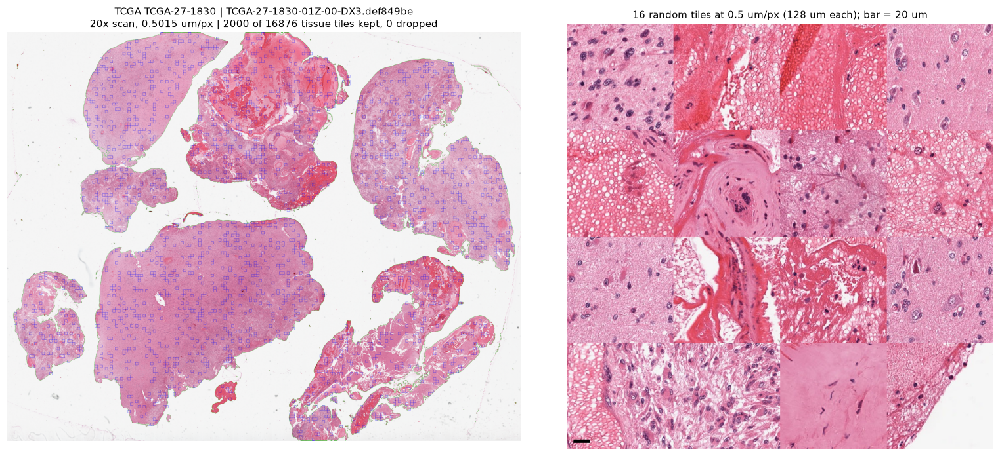

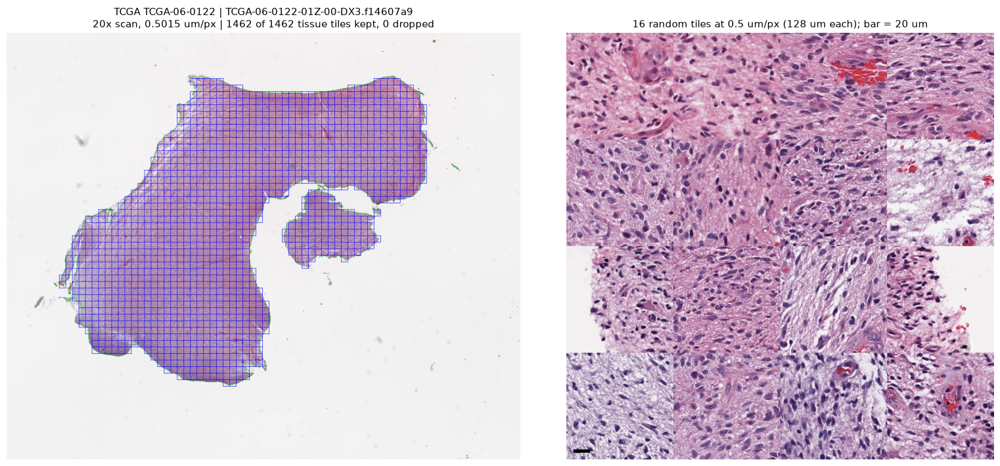

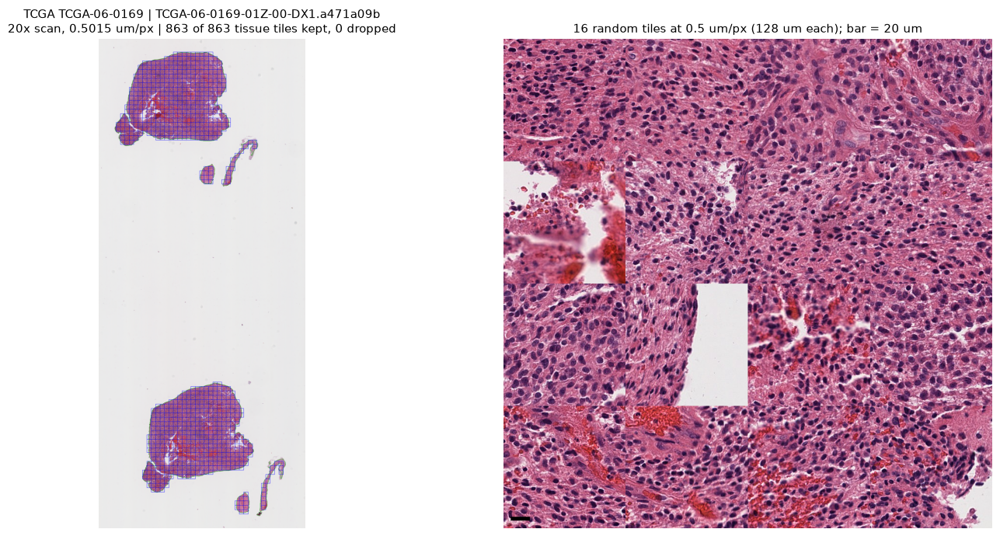

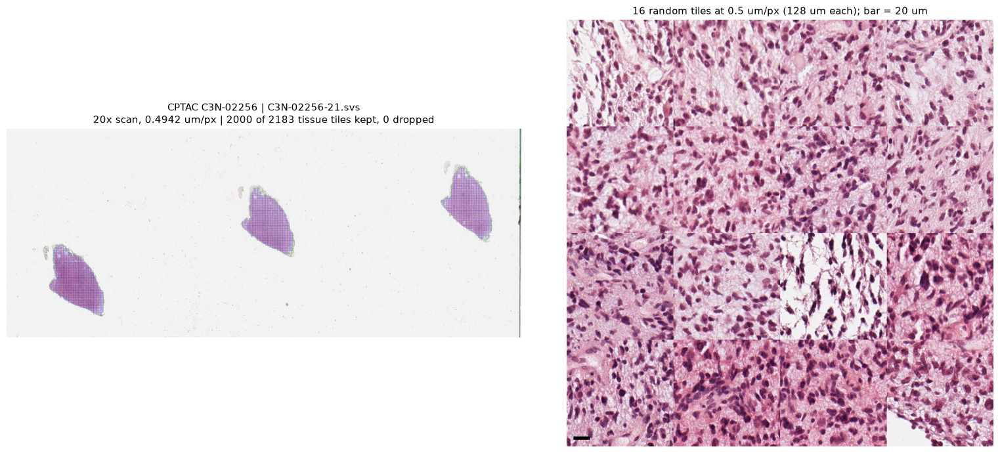

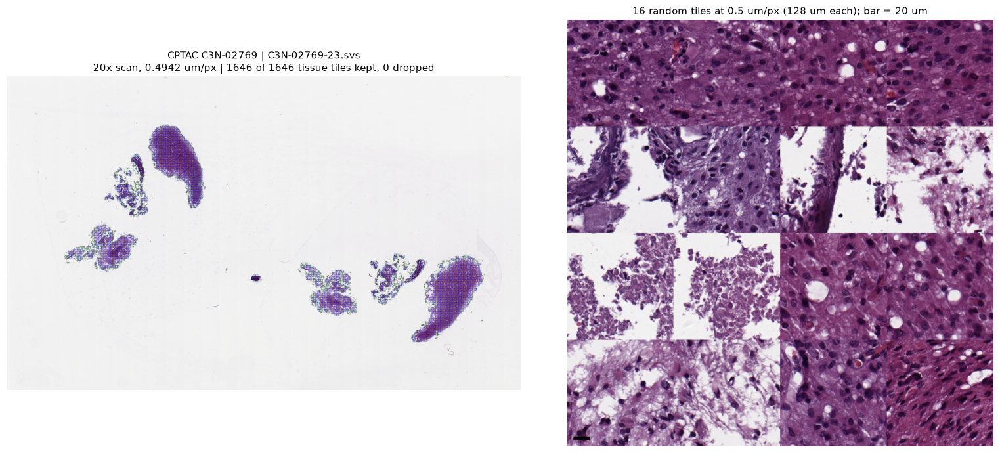

In [ ]:
# Compare tiled slides: QC overview (tissue outline + sampled tiles) next to a grid of random tiles.
# Each tile grid has a 20 um scale bar, so nucleus size can be compared across slides and scanners.
index = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
rows = []
for key in SLIDES:
    match = index[(index.slide_id == key) | index.file_name.str.startswith(key)]
    if len(match) != 1:
        raise ValueError(f"{key}: {len(match)} matching slides in index_{SUBSET}.csv")
    rows.append(match.iloc[0])

for row in rows:
    h5_path = ROOT / row.h5
    qc = Image.open(h5_path.with_name(h5_path.stem + "_qc.png"))
    with h5py.File(h5_path) as h5:
        attrs = dict(h5.attrs)
        n = len(h5["tiles"])
        chosen = np.random.default_rng(SEED).choice(n, size=min(GRID * GRID, n), replace=False)
        tiles = [np.asarray(Image.open(io.BytesIO(h5["tiles"][i].tobytes()))) for i in sorted(chosen)]

    tile_px = int(attrs["tile_px"])
    grid = np.full((GRID * tile_px, GRID * tile_px, 3), 255, dtype=np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, GRID)
        grid[r * tile_px:(r + 1) * tile_px, c * tile_px:(c + 1) * tile_px] = img
    bar_px = int(round(SCALE_BAR_UM / attrs["target_mpp"]))
    grid[-24:-16, 16:16 + bar_px] = 0   # black bar in the bottom-left tile

    scan = "40x" if attrs["source_mpp_x"] < 0.35 else "20x"
    fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 7))
    ax_qc.imshow(qc)
    ax_qc.set_title(f"{row.source} {row.patient_id} | {row.file_name[:32]}\n"
                    f"{scan} scan, {attrs['source_mpp_x']:.4f} um/px | "
                    f"{attrs['n_sampled']} of {attrs['n_tissue_tiles']} tissue tiles kept, "
                    f"{attrs['n_dropped']} dropped", fontsize=11)
    ax_tiles.imshow(grid)
    ax_tiles.set_title(f"{len(tiles)} random tiles at {attrs['target_mpp']} um/px "
                       f"({attrs['tile_um']:.0f} um each); bar = {SCALE_BAR_UM} um", fontsize=11)
    for ax in (ax_qc, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Checking every tile (tiling-v6)

Scores every sampled tile on four measures, then shows, per slide, a contact sheet of all its tiles
(flagged tiles boxed in red, in grid order so neighbouring tiles form continuous tissue) and the 8 worst
tiles for each measure. A summary table of flag counts per slide comes last.

| Measure | Definition | Flag when | Catches |
|---|---|---|---|
| glass | fraction of uncolored glass (saturation < 8, value > 200) | > 0.5 | background, tissue edges |
| dark | fraction of very dark pixels (V < 60) | > 0.2 | folds, debris, ink |
| green | fraction of green pixels | > 0.02 | green marker ink |
| blur | variance of the Laplacian | < 50 | out-of-focus or featureless tiles |

Glass and blur come from `tile.tile_quality`, the same function `tile.py` uses for its quality filter
(it drops tiles with glass > 0.9 or blur < 20). Since tiling-v5, each `.h5` also stores these two scores per
tile. Flags here are looser on purpose: they mark tiles to look at, not tiles to drop.

**How to run it on subset B**

- **Whole subset:** `CHECK_SLIDES = None` and `SHOW_FIGURES = False` gives only the summary table
  (`flag_summary`, sorted by `any_flag`). It decodes every tile (up to 2,000 per slide × 259 slides), so
  expect it to take several minutes.
- **Then a few slides:** set `CHECK_SLIDES` to the slides with the most flags, e.g.
  `flag_summary.slide_id.head(3).tolist()`, and `SHOW_FIGURES = True`. Each slide's contact sheet adds
  several MB to the notebook, so keep the list short.

**Results (tiling-v6, subset B, 258 slides with tiles)**

TCGA-19-1389 has no tiles in tiling-v6 and is skipped. The top of the summary table:

| Slide | Kept tiles | Flagged | Flagged by | Mask threshold (Otsu cut) |
|---|---|---|---|---|
| TCGA-14-1829 DX5 | 2,000 | 861 | blur | 36 |
| TCGA-27-1835 DX2 | 2,000 | 433 | blur | 34 |
| C3N-02255 | 2,000 | 425 | glass | 8 (6) |
| C3N-01851 | 2,000 | 307 | glass | 8 (8) |
| TCGA-19-1390 DX1 | 532 | 295 | glass | 8 (4) |

- **Glass:** the remaining glass-flagged slides are pale or loosely cellular tissue, not background. In the
  Whole-slide view every kept tile on TCGA-19-1390 and C3N-02255 sits on tissue; TCGA-19-1390 is fragmented
  tissue with many small gaps, so many tiles are more than half glass. C3N-01851 has not been viewed yet.
- **Blur:** unchanged from tiling-v5 (the minimum threshold does not affect it).
- **Dark and green:** (fill in from `flag_summary[["dark_flagged", "green_flagged"]].sum()`)

**Results (tiling-v5, subset B, all 259 slides)**

The top of the summary table:

| Slide | Kept tiles | Flagged | Flagged by | Mask threshold |
|---|---|---|---|---|
| TCGA-19-1389 DX1 | 911 | 908 | glass | 2 |
| TCGA-14-1829 DX5 | 2,000 | 861 | blur | 36 |
| TCGA-19-1387 DX1 | 2,000 | 725 | glass | 4 |
| TCGA-19-1390 DX1 | 935 | 698 | glass | 4 |
| C3N-02255 | 2,000 | 516 | glass | 6 |

- **Glass:** the heavily flagged slides all have a mask threshold of 8 or less (subset median 35). On very
  pale slides the lower cut of the three-class Otsu falls in background noise, so the mask covers glass.
  Tiles that are 50–90% glass pass the filter's 0.9 limit and are kept (see Whole-slide view).
- **Blur:** TCGA-14-1829 DX5 is soft across the whole slide (median blur 56). The patient has other slides
  (DX2, DX3, DX6).
- **Glass here vs in the `.h5`:** this cell measures the decoded JPEG; the `glass` stored in the `.h5` was
  measured before encoding and reads lower on pale background (TCGA-19-1387: 725 tiles over 0.5 here,
  209 stored).
**Pilot results (tiling-v3 tiles, about 10,700; flag counts with the original glass rule)**

| Slide | Flagged | What's really there |
|---|---|---|
| TCGA-12-0819 | 7 | One real artifact: a dark debris clump (dark 0.56, blur 16). The rest are tissue-edge tiles. |
| TCGA-14-0817 | 50 | Edge and fragmented tissue at 59–64% glass. One smeared tile (blur 164), not flagged. |
| TCGA-19-2625 | 1,805 | Mostly false alarms (see below); the worst is real: a blank background smudge (glass 1.00, blur 3). |
| TCGA-06-0878 | 40 | Tissue-edge tiles. |
| C3N-01192-21 | 55 | Tissue-edge tiles. |
| C3N-02786-23 | 38 | Tissue-edge tiles. |

Genuinely bad tiles are rare: about 3 of ~10,700 (under 0.1%).

**Fixed: the glass rule.** The original rule (saturation < 20) counted pale tissue as glass: TCGA-19-2625's
tissue sits at saturation 13–20, so 1,805 of its 2,000 tiles were flagged. Background on every pilot slide
sits at 0–3, so the rule is now saturation < 8. Glass flags with the new rule:

| Slide | Old rule | New rule | Highest glass (new rule) |
|---|---|---|---|
| C3N-01192-21 | 55 | 20 | 0.62 |
| C3N-02786-23 | 37 | 3 | 0.53 |
| TCGA-06-0878 | 39 | 5 | 0.54 |
| TCGA-12-0819 | 6 | 0 | 0.47 |
| TCGA-14-0817 | 50 | 14 | 0.59 |
| TCGA-19-2625 | 1,805 | 23 | 0.67 |

The most glass-like tiles under the new rule are all tissue edges with real cells.

**Quality filter check (simulated on the tiling-v3 tiles, became tiling-v4):** glass > 0.9 or blur < 20
drops exactly two tiles: the debris clump on TCGA-12-0819 (blur 16) and the blank smudge on TCGA-19-2625
(blur 3; its glass is only 0.45 because of a faint tint, so blur is what catches it). The next-lowest blur
on any slide is an out-of-focus tissue edge at 25, kept on purpose; real tissue otherwise starts around 83.
The tiling-v4 pilot run dropped exactly those two tiles.

In [ ]:
# Check every tile of the tiled slides: per-tile quality measures, a flagged-tile summary,
# a contact sheet of ALL tiles per slide (flagged tiles boxed in red), and the worst tiles per measure.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
CHECK_SLIDES = None   # None = every slide in index_<SUBSET>.csv; or a list of slide IDs / file-name prefixes
THUMB_PX = 40         # size of each tile in the contact sheet
WORST_N = 8           # full-size examples shown per measure
SHOW_FIGURES = False  # True = contact sheet and worst tiles per slide (keep CHECK_SLIDES short)
FLAGS = {             # measure: (rule, limit) -- a tile is flagged when the rule holds
    "glass":  (">", 0.5),    # fraction of uncolored glass (saturation < 8, value > 200)
    "dark":   (">", 0.2),    # fraction of very dark pixels (folds, debris, ink)
    "green":  (">", 0.02),   # fraction of green pixels (green marker ink)
    "blur":   ("<", 50.0),   # variance of the Laplacian; low = out of focus or featureless
}


def tile_measures(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    glass, blur = tile.tile_quality(img)   # same definitions as tile.py's quality filter
    return {"glass": glass,
            "dark": float((v < 60).mean()),
            "green": float(((h >= 35) & (h <= 85) & (s > 60)).mean()),
            "blur": blur}


def flagged(row):
    return [m for m, (rule, limit) in FLAGS.items()
            if (row[m] > limit if rule == ">" else row[m] < limit)]


checked = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
if CHECK_SLIDES is not None:
    checked = checked[checked.slide_id.isin(CHECK_SLIDES)
                      | checked.file_name.str.startswith(tuple(CHECK_SLIDES))]
    if checked.empty:
        raise ValueError(f"no slides match {CHECK_SLIDES}")
checked = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
checked = checked[checked.n_sampled > 0]   # skip slides with no tiles (e.g. TCGA-19-1389)
summary = []
for slide in tqdm(list(checked.itertuples()), desc="slides"):
    with h5py.File(ROOT / slide.h5) as h5:
        tiles = [np.asarray(Image.open(io.BytesIO(t.tobytes()))) for t in h5["tiles"][:]]
    stats = pd.DataFrame([tile_measures(t) for t in tiles])
    stats["flagged_by"] = stats.apply(flagged, axis=1)
    bad = stats["flagged_by"].str.len() > 0
    summary.append({"slide_id": slide.slide_id, "patient": slide.patient_id,
                    "file": slide.file_name[:23], "tiles": len(tiles), "dropped": slide.n_dropped,
                    **{f"{m}_flagged": int(stats["flagged_by"].apply(lambda f: m in f).sum()) for m in FLAGS},
                    "any_flag": int(bad.sum()), "median_blur": round(stats.blur.median())})

    if not SHOW_FIGURES:
        continue

    # Contact sheet of every tile, flagged ones outlined in red.
    cols = int(np.ceil(np.sqrt(len(tiles) * 1.6)))
    rows = int(np.ceil(len(tiles) / cols))
    sheet = np.full((rows * THUMB_PX, cols * THUMB_PX, 3), 255, np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, cols)
        small = cv2.resize(img, (THUMB_PX, THUMB_PX), interpolation=cv2.INTER_AREA)
        if bad[k]:
            cv2.rectangle(small, (0, 0), (THUMB_PX - 1, THUMB_PX - 1), (255, 0, 0), 2)
        sheet[r * THUMB_PX:(r + 1) * THUMB_PX, c * THUMB_PX:(c + 1) * THUMB_PX] = small
    plt.figure(figsize=(20, 20 * rows / cols))
    plt.imshow(sheet)
    plt.title(f"{slide.source} {slide.patient_id} {slide.file_name[:23]}: all {len(tiles)} tiles, "
              f"{int(bad.sum())} flagged (red)", fontsize=13)
    plt.axis("off")
    plt.show()

    # The worst tiles for each measure, full size, with their values.
    fig, axes = plt.subplots(len(FLAGS), WORST_N, figsize=(2.2 * WORST_N, 2.5 * len(FLAGS)), squeeze=False)
    for ax_row, (m, (rule, limit)) in zip(axes, FLAGS.items()):
        order = stats[m].sort_values(ascending=(rule == "<")).index[:WORST_N]
        for ax, k in zip(ax_row, order):
            ax.imshow(tiles[k])
            ax.set_title(f"{m} {stats.at[k, m]:.2f}" + (" *" if m in stats.at[k, "flagged_by"] else ""),
                         fontsize=9, color="red" if m in stats.at[k, "flagged_by"] else "black")
            ax.axis("off")
    fig.suptitle(f"{slide.patient_id}: worst {WORST_N} tiles per measure (* = past the flag limit)", fontsize=12)
    plt.tight_layout()
    plt.show()

flag_summary = pd.DataFrame(summary).sort_values("any_flag", ascending=False)
display(flag_summary)

slides:   0%|          | 0/258 [00:00<?, ?it/s]

,slide_id,patient,file,tiles,dropped,glass_flagged,dark_flagged,green_flagged,blur_flagged,any_flag,median_blur
214,b7f5df0f-caa4-45a2-9636-badcd1c89316,TCGA-14-1829,TCGA-14-1829-01Z-00-DX5,2000,859,0,0,0,861,861,56
239,0006ae80-5774-4199-bbd0-3c120ed547e6,TCGA-27-1835,TCGA-27-1835-01Z-00-DX2,2000,867,0,0,0,433,433,186
70,C3N-02255-22,C3N-02255,C3N-02255-22.svs,2000,0,425,0,0,0,425,265
63,C3N-01851-21,C3N-01851,C3N-01851-21.svs,2000,12,307,0,0,0,307,366
220,0243c8bf-709e-45ce-9c95-5c092364a963,TCGA-19-1390,TCGA-19-1390-01Z-00-DX1,532,0,295,0,0,0,295,584
...,...,...,...,...,...,...,...,...,...,...,...
68,C3N-02186-22,C3N-02186,C3N-02186-22.svs,2000,0,0,0,0,0,0,779
179,53ce832d-55ef-4158-975d-74c139544309,TCGA-12-3648,TCGA-12-3648-01Z-00-DX3,2000,0,0,0,0,0,0,1169
177,12d0ebe2-91cd-4fa4-8e4f-cc41b1c24abc,TCGA-12-3644,TCGA-12-3644-01Z-00-DX2,2000,2,0,0,0,0,0,907
85,C3N-03182-21,C3N-03182,C3N-03182-21.svs,1028,0,0,0,0,0,0,972


### Dropped tiles (tiling-v6)

**How `tile.py` samples:** it visits a slide's tissue tiles in a random order (fixed per slide by `seed` and
the slide ID). Each visited tile is checked against the quality filter (glass > 0.9 or blur < 20); a tile that
fails is dropped and the next tile in the order is checked. Sampling stops when 2,000 tiles are kept or the
tissue tiles run out, so `n_examined = n_sampled + n_dropped`. On capped slides, tiles past the stopping
point are never checked.

This cell lists every slide that dropped tiles, sorted by the share of examined tiles dropped, then shows a
random sample of `MAX_SHOWN` dropped tiles for the `TOP_N` worst slides (or for `DROP_SLIDES`). Dropped tiles
are not stored in the `.h5` files, only their coordinates (`dropped_coords`), so they are re-read from the
`.svs`.

**Results (tiling-v6, subset B):** 61 of 259 slides dropped tiles, 7,093 in total. The glass drops are gone:
the mask no longer covers glass, so TCGA-19-1791 dropped 1 tile instead of 4,068. What is left is the blur
rule, on the same slides as in tiling-v5 (TCGA-12-0821 DX3, 14-1827 DX2, 27-1835 DX2, 14-1829 DX5,
27-1836 DX4), plus TCGA-06-0881 DX1, 27-1831 DX3 and 28-1746 in the top 8:

- Flat color with no structure (blur 1–5), e.g. TCGA-14-1827 DX2, and flat pink areas with dust specks on
  TCGA-27-1831 DX3 (blur 3–17). Correct drops.
- Out-of-focus tissue with nuclei still visible (blur about 4–18), e.g. TCGA-12-0821 DX3, 06-0881 DX1 and
  the dense, dark tissue on TCGA-28-1746. Real tissue, dropped by the blur rule.

The two kinds still overlap (flat pink on TCGA-27-1831 at blur 17, recognizable tissue at blur 4), so the
conclusion below is unchanged.

**Results (tiling-v5, subset B):** 63 of 259 slides dropped tiles, 12,036 in total, 11,822 of them TCGA.
The dropped tiles are of three kinds:

| Kind | Slides | Scores | Verdict |
|---|---|---|---|
| Glass, dust and bubbles | TCGA-19-1791, 19-1390, 19-1387 (mask threshold 3–4) | glass 0.90–0.99 | Correct: the mask covered glass and the filter removed it |
| Flat, featureless color | TCGA-14-1827 DX2, 27-1835 DX2 | blur 1–5 | Correct; some show a straight scanner seam |
| Out-of-focus tissue, nuclei still visible | TCGA-12-0821 DX3, 14-1829 DX5, 27-1836 DX4 | blur about 3–19 | Real tissue, dropped by the blur rule |

The last two kinds overlap at blur 3–5, so no lower `min_blur` separates them cleanly.

**Proposed: keep `min_blur` at 20.** On TCGA-12-0821 the dropped tiles come from one out-of-focus region and
the slide still reaches 2,000 tiles. The heavily blurred slides are all TCGA and cluster by tissue source
site, while CPTAC (the test cohort) is sharp, so keeping blurred tiles risks a site shortcut. Robustness to
blur can come from blur augmentation in training instead.

61 of 259 slides dropped tiles; 7093 dropped in total


,slide_id,patient_id,file_name,mask_threshold,n_tissue_tiles,n_examined,n_dropped,drop_pct,n_sampled
163,a12ed831-9ee6-48cb-9f33-af55441ccb06,TCGA-12-0821,TCGA-12-0821-01Z-00-DX3,46.0,12865,4123,2123,51.5,2000
208,dbbba1b5-c2c3-4294-8488-5e5fe4babc72,TCGA-14-1827,TCGA-14-1827-01Z-00-DX2,42.0,12472,2889,889,30.8,2000
240,0006ae80-5774-4199-bbd0-3c120ed547e6,TCGA-27-1835,TCGA-27-1835-01Z-00-DX2,34.0,14349,2867,867,30.2,2000
214,b7f5df0f-caa4-45a2-9636-badcd1c89316,TCGA-14-1829,TCGA-14-1829-01Z-00-DX5,36.0,8135,2859,859,30.0,2000
242,049624f0-9245-4c6c-acd3-9fc37ee9603b,TCGA-27-1836,TCGA-27-1836-01Z-00-DX4,39.0,14978,2539,539,21.2,2000
...,...,...,...,...,...,...,...,...,...
210,15747aa7-bef8-4d18-baa9-a396661df3f6,TCGA-14-1829,TCGA-14-1829-01Z-00-DX3,29.0,9663,2001,1,0.0,2000
103,23b6a9db-fd81-4ee8-a683-6f3c0288bef3,TCGA-02-0021,TCGA-02-0021-01Z-00-DX2,49.0,13250,2001,1,0.0,2000
205,c82ea72a-a309-4542-8bd0-56fe3f805f55,TCGA-14-1795,TCGA-14-1795-01Z-00-DX3,34.0,15833,2001,1,0.0,2000
186,2f67e999-7308-42b8-b441-d818dc041ea4,TCGA-12-3652,TCGA-12-3652-01Z-00-DX1,39.0,15155,2001,1,0.0,2000


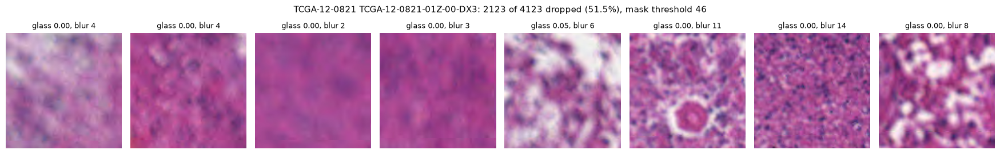

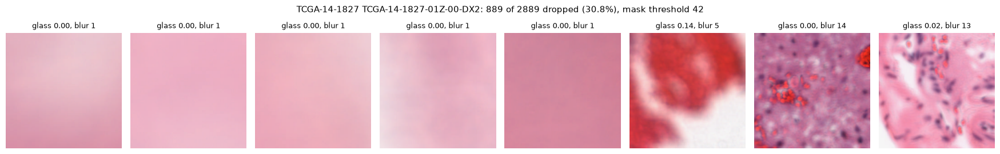

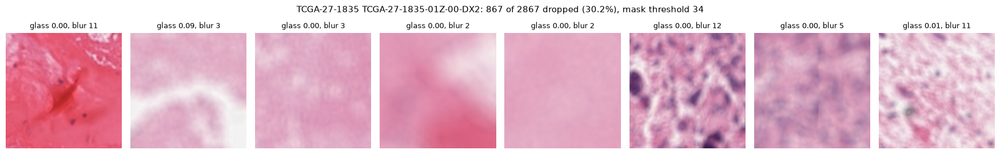

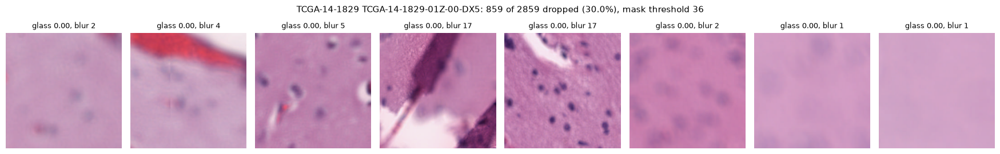

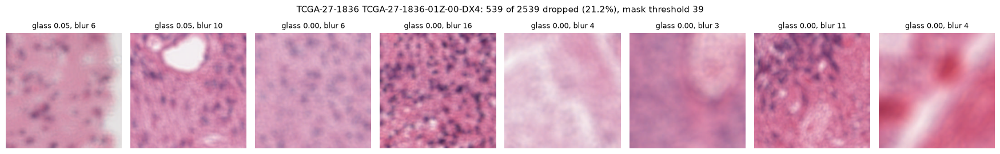

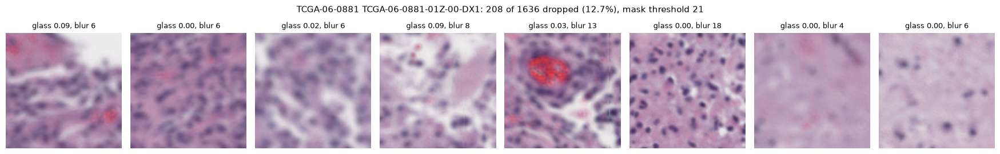

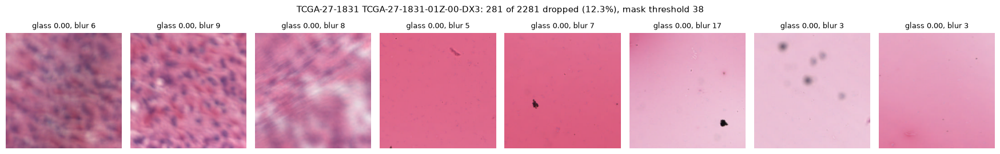

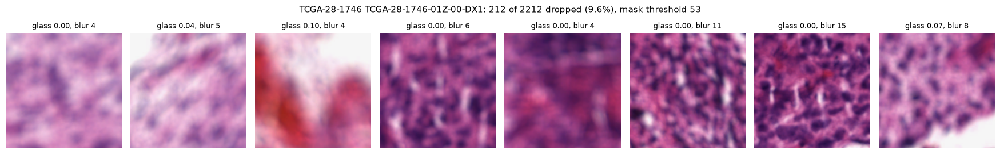

In [ ]:
# Quality-filter results: per-slide drop summary, then a sample of the dropped tiles for the worst slides.
# Dropped tiles are not stored in the .h5 files (only their coordinates), so they are re-read from the slide.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
DROP_SLIDES = None   # None = the TOP_N slides with the highest share dropped; or a list of slide IDs / prefixes
TOP_N = 8            # slides shown when DROP_SLIDES is None
MAX_SHOWN = 8        # dropped tiles shown per slide (random sample)

results = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
results["drop_pct"] = (100 * results.n_dropped / results.n_examined).round(1)
drops = (results[results.n_dropped > 0]
         .sort_values("drop_pct", ascending=False)
         [["slide_id", "patient_id", "file_name", "mask_threshold", "n_tissue_tiles",
           "n_examined", "n_dropped", "drop_pct", "n_sampled"]])
print(f"{len(drops)} of {len(results)} slides dropped tiles; {results.n_dropped.sum()} dropped in total")
display(drops.assign(file_name=drops.file_name.str[:23]))

if DROP_SLIDES is None:
    show = drops.head(TOP_N)
else:
    show = drops[drops.slide_id.isin(DROP_SLIDES) | drops.file_name.str.startswith(tuple(DROP_SLIDES))]
    if show.empty:
        raise ValueError(f"no slides with drops match {DROP_SLIDES}")

for slide in show.itertuples():
    row = results[results.slide_id == slide.slide_id].iloc[0]
    with h5py.File(ROOT / row.h5) as h5:
        attrs = dict(h5.attrs)
        dropped = h5["dropped_coords"][:]
    pick = np.random.default_rng(SEED).choice(len(dropped), size=min(MAX_SHOWN, len(dropped)), replace=False)
    wsi = WSIReader.open(paths_for(ROOT, {"source": row.source, "patient_id": row.patient_id,
                                          "slide_id": row.slide_id, "file_name": row.file_name})[0])
    px = int(attrs["tile_px"])
    fig, axes = plt.subplots(1, MAX_SHOWN, figsize=(2.2 * MAX_SHOWN, 2.8), squeeze=False)
    for ax in axes[0]:
        ax.axis("off")
    for ax, k in zip(axes[0], sorted(pick)):
        x, y = dropped[k]
        img = np.ascontiguousarray(wsi.read_rect((int(x), int(y)), (px, px), attrs["target_mpp"], "mpp",
                                                 coord_space="resolution")[..., :3])
        glass, blur = tile.tile_quality(img)
        ax.imshow(img)
        ax.set_title(f"glass {glass:.2f}, blur {blur:.0f}", fontsize=9)
    fig.suptitle(f"{row.patient_id} {row.file_name[:23]}: {slide.n_dropped} of {slide.n_examined} dropped "
                 f"({slide.drop_pct}%), mask threshold {slide.mask_threshold:.0f}", fontsize=11)
    plt.tight_layout()
    plt.show()

### Whole-slide view (tiling-v6)

For each slide in `VIEW_SLIDES`: the full slide at `THUMB_MPP` next to the same thumbnail with kept tiles
(blue) and dropped tiles (red). Only visited tiles are drawn, so on capped slides some tissue has no box.

**Results (tiling-v6)**

- **TCGA-19-1791 DX1** (Otsu cut 3, threshold raised to 8): 1,028 tiles kept, 1 dropped. Every tile is on
  one of the three tissue sections; the glass is no longer in the mask.
- **TCGA-19-1390 DX1** (Otsu 4 → 8): 532 tiles kept, all on tissue. The tissue is fragmented and loosely
  cellular, which explains its glass flags. A few small, faint fragments at the edges are not tiled.
- **TCGA-19-1787 DX1** (Otsu 6 → 8): 1,219 kept; all three sections covered, nothing on glass.
- **C3N-02255** (Otsu 6 → 8): 2,000 kept on the two sections, nothing on glass.
- **TCGA-19-1389 DX1** (Otsu 2 → 8): no tissue tiles. The tissue is almost unstained, so it stays below
  the minimum, and the slide is written with 0 tiles, which excludes it.

**Results (tiling-v5)**

- **TCGA-19-1791 DX1** (mask threshold 3): the mask spread over the glass, but the filter dropped those tiles
  (red). The 1,137 kept tiles cover the three tissue sections and nothing else.
- **TCGA-19-1389 DX1** (mask threshold 2): the whole image is tiled, glass included, and only 1 tile was
  dropped. The tissue is almost unstained, barely darker than the glass, so most kept tiles show nothing
  useful. This slide should be excluded rather than fixed.

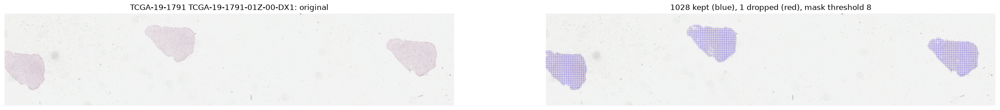

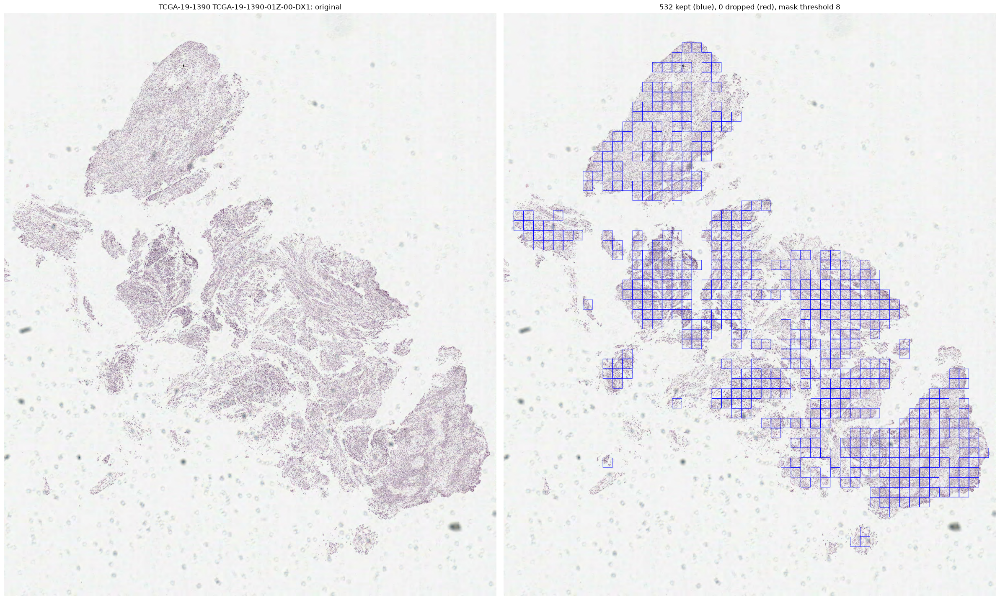

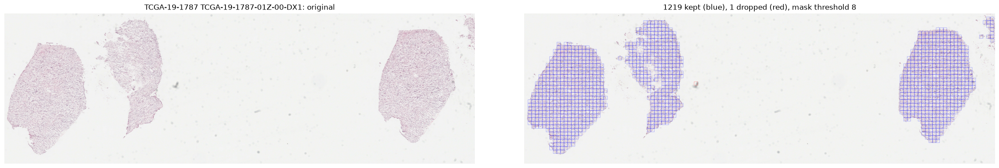

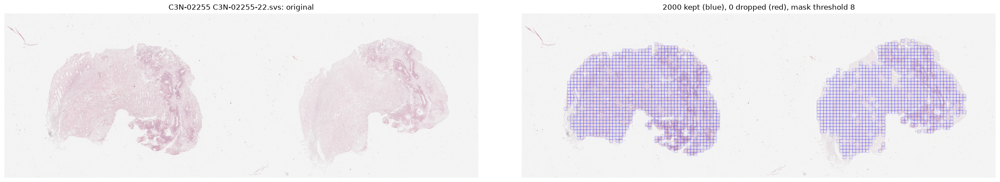

In [ ]:
# Whole-slide view: the original thumbnail next to the same thumbnail with
# kept tiles (blue) and dropped tiles (red), one row per slide.
VIEW_SLIDES = ["TCGA-19-1791-01Z-00-DX1", "TCGA-19-1390-01Z-00-DX1",
               "TCGA-19-1787-01Z-00-DX1", "C3N-02255"]
THUMB_MPP = 4.0                     # thumbnail resolution in um/px (lower = sharper and bigger)

results = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
for key in VIEW_SLIDES:
    row = results[(results.slide_id == key) | results.file_name.str.startswith(key)].iloc[0]
    with h5py.File(ROOT / row.h5) as h5:
        attrs = dict(h5.attrs)
        kept, dropped = h5["coords"][:], h5["dropped_coords"][:]

    wsi = WSIReader.open(paths_for(ROOT, {"source": row.source, "patient_id": row.patient_id,
                                          "slide_id": row.slide_id, "file_name": row.file_name})[0])
    original = np.ascontiguousarray(wsi.slide_thumbnail(THUMB_MPP, "mpp")[..., :3])
    overlay = original.copy()
    scale = attrs["target_mpp"] / THUMB_MPP             # tile coords are at target_mpp
    size = int(round(attrs["tile_px"] * scale))
    for coords, color in ((kept, (0, 0, 255)), (dropped, (255, 0, 0))):
        for x, y in (coords * scale).round().astype(int):
            cv2.rectangle(overlay, (x, y), (x + size - 1, y + size - 1), color, 1)

    height, width = original.shape[:2]
    fig, (ax_orig, ax_tiles) = plt.subplots(1, 2, figsize=(24, 12 * height / width))
    ax_orig.imshow(original)
    ax_orig.set_title(f"{row.patient_id} {row.file_name[:23]}: original", fontsize=12)
    ax_tiles.imshow(overlay)
    ax_tiles.set_title(f"{len(kept)} kept (blue), {len(dropped)} dropped (red), "
                       f"mask threshold {row.mask_threshold:.0f}", fontsize=12)
    for ax in (ax_orig, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Findings and next steps (tiling-v6, subset B)

1. **Mask on very pale slides: fixed in tiling-v6.** The mask threshold is never below 8. Six slides had an
   Otsu cut below 8 (TCGA-19-1389, 19-1791, 19-1387, 19-1390, 19-1787, C3N-02255); their kept tiles are now
   all on tissue, and total drops fell from 12,036 to 7,093. The other 253 slides are unchanged.
2. **Excluded: TCGA-19-1389 DX1** (almost unstained; 0 tiles in tiling-v6). Filter with
   `index[index.n_sampled > 0]`. Consider also excluding **TCGA-14-1829 DX5** (out of focus throughout;
   the patient has other slides).
3. **Blur filter:** keep `min_blur` at 20; add blur augmentation in training if needed.
4. **Still to check:** dark and green flag totals (pen marks), and C3N-01851 in the Whole-slide view.
5. **Subset A:** Carlos tiles from the tiling-v6 commit (`3c106a7`).
6. **Training notes:** stain differs between TCGA and CPTAC; some slides have only about 100 kept tiles,
   others 2,000; serial sections give near-duplicate tiles. Pool each patient's slides and weight by patient.